# Guía end-to-end — ¿Quién va a cancelar su reserva?

**Introducción al Análisis Avanzado de Datos con Python** · Univalle · Material de apoyo para el proyecto final

Este notebook es un **proyecto completo y resuelto**, de principio a fin, como los que se encuentran en Kaggle, pero hecho con el cuidado que pedimos en el curso: sin fuga de información, con línea base y con una lectura honesta de los resultados.

**Para qué sirve.** Para tener a la vista, en un solo lugar, cómo se ve un proyecto de Machine Learning real: desde que se abre el archivo hasta que se guarda el modelo y se escribe la conclusión. Úselo como **ejemplo y como guía** mientras trabaja la **plantilla del proyecto** (`proyecto/plantilla_proyecto.ipynb`), que tiene exactamente las mismas secciones, pero vacías, para su propio dataset.

> 💾 **Antes de ejecutar:** menú *Archivo → Guardar una copia en Drive* y trabaje en esa copia. Si Colab avisa que el notebook no es de Google, elija *Ejecutar de todos modos*. Corre completo en 5 a 8 minutos (*Entorno de ejecución → Ejecutar todo*).

## Cómo leer esta guía

- **No hay que completar nada:** todo el código está escrito y comentado. Léalo, ejecútelo y cambie cosas para ver qué pasa.
- Varios modelos de esta guía **todavía no los hemos visto en clase**. Aparecen como **vitrina**: una intuición, una figura y una ficha corta, para que sepa que existen y qué hacen. A fondo los vemos en la sesión que dice cada sección. Si algo no le queda claro todavía, no se preocupe: es normal y es intencional.
- 🔍 **Predice** → piense su respuesta antes de ejecutar la celda siguiente · 👀 **Mire** → deténgase en la figura · 📘 **Para entender** → explicación conceptual · 📦 **En su proyecto** → qué hacer en su plantilla.

| Sección | Qué se hace | Se ve a fondo en | Entrega del proyecto |
|---|---|---|---|
| 1–4 | Problema, primera mirada, exploración, columnas con fuga | S1–S3 | E1 |
| 5–6 | Limpieza y *feature engineering* | S2–S3 | E2 |
| 7–9 | Partición, preprocesamiento en `Pipeline`, línea base y métricas | S3, S5–S6 | E2 |
| 10 | Desbalance de clases | S5–S6 | E2 |
| 11 | Modelos: árbol, regresión logística y vitrina (k-NN, bosque, boosting) | S1, S5, S6, S11 | E2 / E4 |
| 12 | Paréntesis: cuando la *y* es un número (regresión lineal) | S4 | E2 |
| 13 | Agrupar sin la *y*: PCA y K-means | S7–S9 | E3 |
| 14–18 | Validación cruzada, búsqueda de hiperparámetros, prueba final, interpretación, guardar el modelo | S10–S11 | E4 |
| 19 | Límites y conclusión de negocio | S12 | Presentación |

## 0. Setup

Baja del repositorio del curso el dataset y `figuras.py`. Si ya están en el disco de Colab, no los vuelve a bajar.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
SEMILLA = 42            # la misma semilla en todo el notebook: así los resultados se pueden repetir
INICIO = time.time()

REPO = "https://raw.githubusercontent.com/Nitobest/curso-aad-python/main/"
ARCHIVOS = {"hotel_bookings.csv.gz": "datos/hotel_bookings.csv.gz",
            "figuras.py": "tools/figuras.py"}

def asegurar_datos(archivo, url_repo):
    """Deja un archivo en el disco de Colab: lo baja del repositorio del curso si aún no está."""
    from pathlib import Path
    import requests
    if Path(archivo).exists():
        return True
    try:
        r = requests.get(url_repo, timeout=120)
        if r.ok:
            Path(archivo).write_bytes(r.content)
            return True
    except Exception:
        pass
    print(f"⚠️ No pude bajar {archivo}. Use el Plan B (celda siguiente).")
    return False

for archivo, ruta in ARCHIVOS.items():
    asegurar_datos(archivo, REPO + ruta)
try:
    import figuras as fg
except ModuleNotFoundError:   # Plan B: GitHub no respondió y no llegó figuras.py
    from google.colab import files
    print("⚠️ No llegó figuras.py: súbalo (el profesor lo comparte por el canal del curso).")
    files.upload()
    import figuras as fg

try:                          # imbalanced-learn (SMOTE) viene en Colab; si no está, se instala
    import imblearn
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"], check=True)
    import imblearn
print("Listo:", ", ".join(ARCHIVOS), "| imbalanced-learn", imblearn.__version__)

Listo: hotel_bookings.csv.gz, figuras.py | imbalanced-learn 0.14.2


<details><summary><b>Plan B</b> — si la celda anterior avisó que no pudo bajar algún archivo</summary>

La celda siguiente revisa sola qué falta y solo en ese caso le pide subirlo (el profesor comparte los archivos por el canal del curso).
</details>

In [2]:
# Plan B: solo actúa si falta algún archivo. Con "Ejecutar todo" no se detiene.
from pathlib import Path
faltan = [a for a in ARCHIVOS if not Path(a).exists()]
if not faltan:
    print("✓ Todo disponible: no hace falta el Plan B.")
else:
    from google.colab import files
    print("⚠️ Faltan:", faltan, "→ súbalos")
    files.upload()

✓ Todo disponible: no hace falta el Plan B.


Tres figuras pequeñas que esta guía usa varias veces. Las demás vienen de `figuras.py`, como en las sesiones.

In [3]:
# --- Figuras propias de esta guía (con la paleta del curso) ----------------------------
def tasa_por_categoria(df, col, col_y="is_canceled", orden=None, minimo=0, titulo=None, leyenda=""):
    """Barras: % de cancelación en cada categoría de `col`; el número sobre la barra es cuántas reservas hay."""
    t = df.groupby(col)[col_y].agg(["mean", "size"])
    t = t[t["size"] >= minimo]
    t = t.loc[orden] if orden is not None else t.sort_values("mean")
    fig, ax = plt.subplots(figsize=(min(1.0 * len(t) + 3, 12), 3.8))
    barras = ax.bar(t.index.astype(str), t["mean"] * 100, color=fg.ROJO, alpha=0.85)
    ax.axhline(df[col_y].mean() * 100, color=fg.NEGRO, ls="--", lw=1)
    ax.text(len(t) - 0.5, df[col_y].mean() * 100 + 1.5, f"promedio {df[col_y].mean():.0%}", ha="right", fontsize=9)
    for b, n in zip(barras, t["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{n:,}".replace(",", " "), ha="center", fontsize=8, color=fg.GRIS)
    ax.set_ylabel("% que cancela"); ax.set_ylim(0, 105); ax.set_xlabel(col)
    ax.set_title(titulo or f"¿Cuánto se cancela según {col}?")
    plt.xticks(rotation=30 if len(t) > 6 else 0, ha="right" if len(t) > 6 else "center")
    fig.tight_layout()
    return fg._leyenda(fig, leyenda or "la línea punteada es el promedio general; el número gris, cuántas reservas hay en cada barra "
                                       "(una barra alta con pocas reservas vale poco).")

def hist_por_clase(df, col, col_y="is_canceled", recorte=0.98, xlabel=None, leyenda=""):
    """Histogramas de `col` para las reservas que se quedan (azul) y las que cancelan (rojo)."""
    lim = df[col].quantile(recorte)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for v, c, e in ((0, fg.AZUL, "se queda"), (1, fg.ROJO, "cancela")):
        s = df.loc[df[col_y] == v, col]
        ax.hist(s.clip(upper=lim), bins=50, alpha=0.55, color=c, density=True, label=f"{e} · mediana {s.median():.0f}")
    ax.set_xlabel(xlabel or col); ax.set_ylabel("densidad"); ax.legend()
    ax.set_title(f"{xlabel or col}: ¿se ve distinto en las reservas que cancelan?")
    fig.tight_layout()
    return fg._leyenda(fig, leyenda or "si las dos montañas se separan, la variable ayuda a distinguir; si se superponen, aporta poco "
                                       "(la última barra junta todo lo que pasa del percentil 98).")

def barras_horizontales(serie, titulo, xlabel, leyenda, color=None):
    """Barras horizontales ordenadas (importancias, coeficientes, métricas por escenario)."""
    s = serie.sort_values()
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(s) + 1.3))
    colores = color or [fg.ROJO if v >= 0 else fg.AZUL for v in s.values]
    ax.barh(s.index.astype(str), s.values, color=colores)
    ax.axvline(0, color=fg.NEGRO, lw=0.6); ax.set_xlabel(xlabel); ax.set_title(titulo)
    fig.tight_layout()
    return fg._leyenda(fig, leyenda)

print("Figuras de la guía listas.")

Figuras de la guía listas.


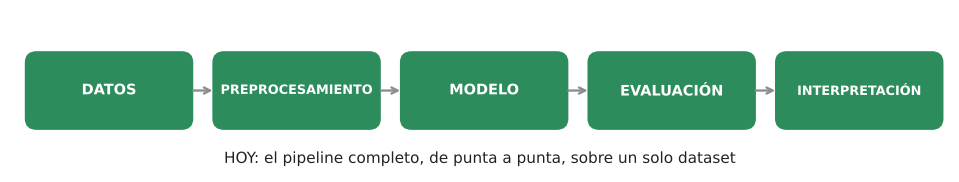

In [4]:
fg.pipeline("todas", modulo=2, subtitulo="HOY: el pipeline completo, de punta a punta, sobre un solo dataset");

## 1. El problema: ¿quién va a cancelar? 📦 E1

**El caso.** Un hotel en Cartagena o en Santa Marta vive el mismo dolor que cualquier hotel del mundo: una parte de las reservas se cancela, muchas a última hora. Cada habitación que queda vacía es plata perdida y no se puede guardar para mañana. Por eso los hoteles **sobrevenden** (aceptan más reservas que habitaciones) o llaman a los huéspedes con riesgo de cancelar para confirmarles. Las dos estrategias necesitan lo mismo: **saber, al momento de la reserva, qué tan probable es que se cancele**.

**Los datos.** *Hotel Booking Demand*: 119 390 reservas reales de dos hoteles de Portugal (uno de ciudad, en Lisboa, y uno de playa, en el Algarve), con llegadas entre julio de 2015 y agosto de 2017. Fuente: Antonio, Almeida y Nunes (2019), *Hotel booking demand datasets*, *Data in Brief* 22, 41–49, DOI 10.1016/j.dib.2018.11.126 · licencia CC BY 4.0. Es uno de los datasets más usados en Kaggle para practicar clasificación.

| Pregunta | Respuesta para este proyecto |
|---|---|
| ¿Qué es una fila? | Una reserva |
| ¿Cuál es la *y*? | `is_canceled`: 1 si la reserva se canceló (o el huésped no llegó), 0 si llegó |
| ¿Qué tipo de problema es? | **Clasificación binaria** (supervisado) |
| ¿En qué momento se usa el modelo? | **Cuando entra la reserva**. Esto define qué columnas son legales (sección 4) |
| ¿Quién usa el resultado? | El área de *revenue management* del hotel: decide cuánto sobrevender y a quién llamar |

### 📘 Para entender — la métrica se elige pensando en los errores

Antes de abrir los datos conviene pensar **qué cuesta cada error**, porque eso decide la métrica:

| | El modelo dice "va a cancelar" | El modelo dice "va a llegar" |
|---|---|---|
| **Cancela de verdad** | ✅ Acierto: el hotel sobrevende esa habitación y no la pierde | ❌ **Falso negativo**: habitación vacía, ingreso perdido |
| **Llega de verdad** | ❌ **Falso positivo**: el hotel sobrevendió y el huésped llega sin habitación (reubicarlo cuesta plata y reputación) | ✅ Acierto |

Los dos errores cuestan, y no lo mismo. Por eso **no** vamos a usar *accuracy* como métrica principal (en la sección 9 vemos por qué engaña). Usaremos:

- **AUC** para **comparar modelos**: mide qué tan bien ordena el modelo las reservas de más a menos riesgo, sin haber elegido todavía un umbral (Sesión 6).
- **Recall, precisión y F1** para **decidir el umbral** con el que el hotel actúa (Sesiones 5 y 6).

> 📦 **En su proyecto (E1):** escriba esta misma tabla para su dataset: qué es una fila, cuál es la *y*, qué tipo de problema es, **en qué momento se usaría el modelo** y qué cuesta cada error.

## 2. Primera mirada 📦 E1

🔍 **Predice:** de cada 100 reservas, ¿cuántas cree que se cancelan? Escriba un número antes de seguir.

In [5]:
df_original = pd.read_csv("hotel_bookings.csv.gz")      # pandas lee el .gz directo, sin descomprimir
print("Filas y columnas:", df_original.shape)
df_original.head()

Filas y columnas: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:
# Tipo de cada columna, cuántos vacíos tiene y un ejemplo de valor
resumen = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "vacíos": df_original.isna().sum(),
    "% vacíos": (df_original.isna().mean() * 100).round(1),
    "valores distintos": df_original.nunique(),
    "ejemplo": df_original.iloc[0],
})
resumen

,tipo,vacíos,% vacíos,valores distintos,ejemplo
hotel,str,0,0.0,2,Resort Hotel
is_canceled,int64,0,0.0,2,0
lead_time,int64,0,0.0,479,342
arrival_date_year,int64,0,0.0,3,2015
arrival_date_month,str,0,0.0,12,July
arrival_date_week_number,int64,0,0.0,53,27
arrival_date_day_of_month,int64,0,0.0,31,1
stays_in_weekend_nights,int64,0,0.0,17,0
stays_in_week_nights,int64,0,0.0,35,0
adults,int64,0,0.0,14,2


In [7]:
print(f"Cancelan: {df_original['is_canceled'].mean():.1%} de las reservas")
print(f"Filas idénticas a otra fila: {df_original.duplicated().sum():,}  ({df_original.duplicated().mean():.1%})")

Cancelan: 37.0% de las reservas


Filas idénticas a otra fila: 31,994  (26.8%)


**Lectura.** 32 columnas y casi 120 mil reservas. Cuatro columnas tienen vacíos: `company` y `agent` casi siempre, `country` y `children` muy poco. Un 37 % de las reservas se cancela. Y hay algo que no se puede dejar pasar: **más de una de cada cuatro filas es idéntica a otra**. Volvemos a eso en la limpieza (sección 5), porque cambia la historia.

| Grupo de columnas | Columnas |
|---|---|
| La reserva | `hotel`, `lead_time` (días entre la reserva y la llegada), `arrival_date_*`, `stays_in_weekend_nights`, `stays_in_week_nights`, `meal`, `reserved_room_type`, `deposit_type`, `adr` (tarifa promedio por noche, en euros) |
| Quién reserva | `adults`, `children`, `babies`, `country`, `customer_type`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` |
| Por dónde llegó | `market_segment`, `distribution_channel`, `agent`, `company` |
| Lo que pasó después | `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`… → **ojo, sección 4** |

## 3. Exploración guiada por preguntas 📦 E1

Un EDA no es "hacer todas las gráficas posibles". Es hacerle **preguntas** a los datos, una por una, y escribir qué respondieron. Cada pregunta de esta sección termina con una **lectura** de una o dos frases.

Para explorar usamos los datos **sin duplicados** (sección 5 explica por qué). Explorar todo el dataset antes de partirlo es aceptable **mientras solo miremos**: ninguna decisión que tome el modelo sale de aquí. Lo que aprende de los datos (medianas, escalas, categorías) se ajustará solo con entrenamiento, dentro del `Pipeline` (sección 8).

In [8]:
eda = df_original.drop_duplicates().copy()
print(f"Reservas únicas: {len(eda):,}  ·  cancelan: {eda['is_canceled'].mean():.1%}")

Reservas únicas: 87,396  ·  cancelan: 27.5%


### Pregunta 1 — ¿Se cancela igual en los dos hoteles?

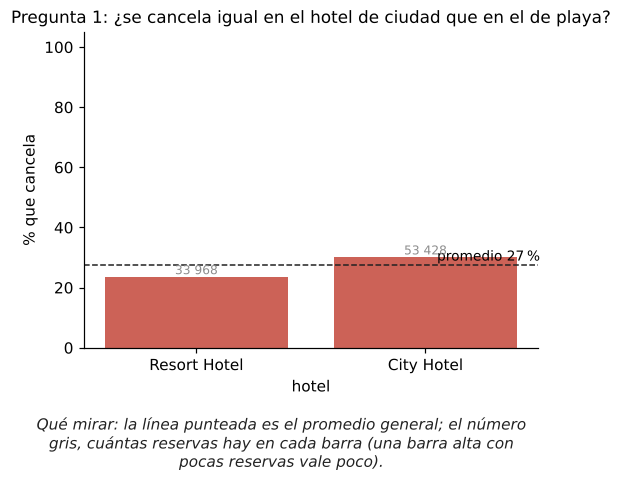

In [9]:
tasa_por_categoria(eda, "hotel", titulo="Pregunta 1: ¿se cancela igual en el hotel de ciudad que en el de playa?");

**Lectura.** El hotel de ciudad cancela bastante más que el de playa. Ya sabemos que `hotel` va a ser una variable útil y que los dos negocios se comportan distinto.

### Pregunta 2 — ¿Las reservas hechas con mucha anticipación se cancelan más?

👀 **Mire** la figura siguiente: `lead_time` son los días entre el momento de reservar y el día de llegada.

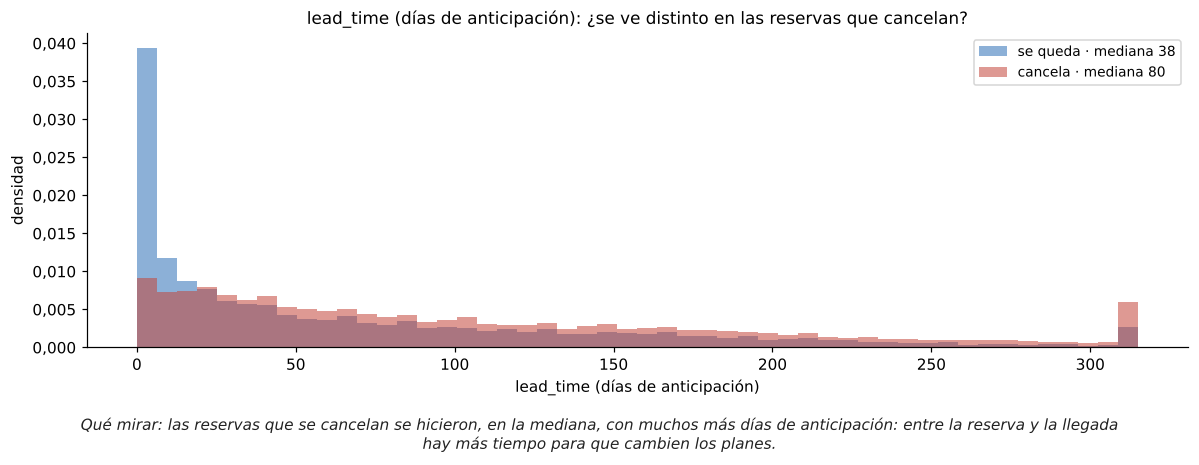

In [10]:
hist_por_clase(eda, "lead_time", xlabel="lead_time (días de anticipación)",
               leyenda="las reservas que se cancelan se hicieron, en la mediana, con muchos más días de anticipación: "
                       "entre la reserva y la llegada hay más tiempo para que cambien los planes.");

**Lectura.** Sí: la anticipación es probablemente la variable más informativa de todas. Además está muy **sesgada a la derecha** (muchas reservas cercanas y una cola larga de reservas con un año de anticipación). Para los modelos lineales eso importa; para los árboles no (sección 6).

### Pregunta 3 — ¿Hay temporadas?

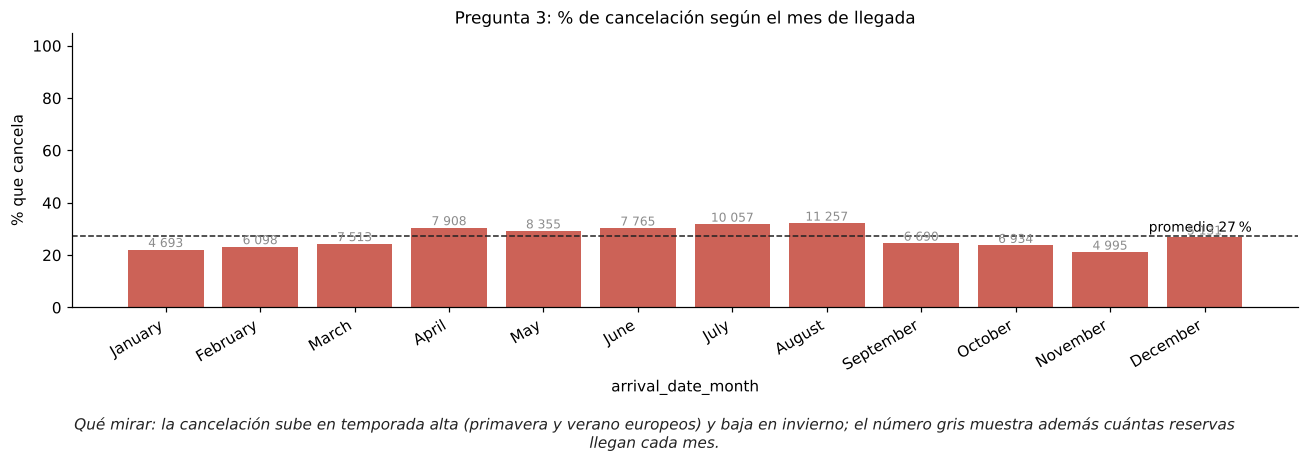

In [11]:
MESES = ["January", "February", "March", "April", "May", "June", "July", "August",
         "September", "October", "November", "December"]
tasa_por_categoria(eda, "arrival_date_month", orden=MESES, titulo="Pregunta 3: % de cancelación según el mes de llegada",
                   leyenda="la cancelación sube en temporada alta (primavera y verano europeos) y baja en invierno; "
                           "el número gris muestra además cuántas reservas llegan cada mes.");

**Lectura.** Hay estacionalidad: en los meses de más demanda se cancela más. El mes de llegada entra al modelo.

### Pregunta 4 — ¿Influye por dónde llegó la reserva y qué depósito dejó?

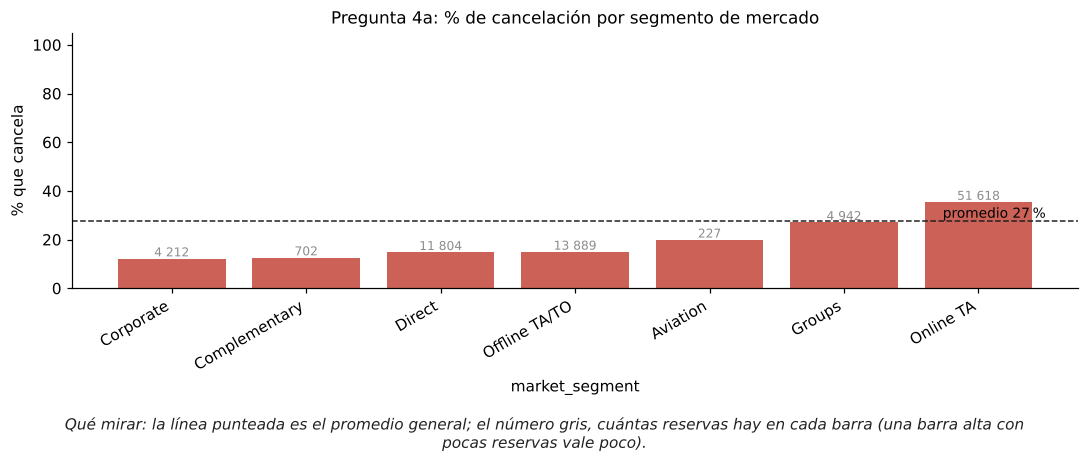

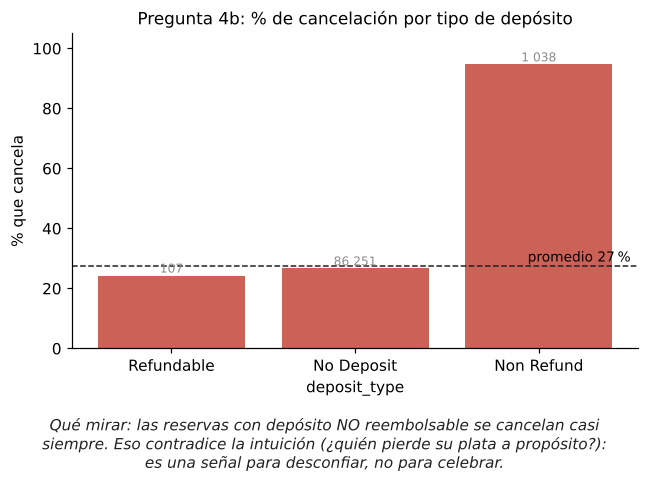

In [12]:
tasa_por_categoria(eda, "market_segment", minimo=100, titulo="Pregunta 4a: % de cancelación por segmento de mercado");
tasa_por_categoria(eda, "deposit_type", titulo="Pregunta 4b: % de cancelación por tipo de depósito",
                   leyenda="las reservas con depósito NO reembolsable se cancelan casi siempre. Eso contradice la intuición "
                           "(¿quién pierde su plata a propósito?): es una señal para desconfiar, no para celebrar.");

**Lectura.** Las agencias de viaje en línea (*Online TA*) cancelan más que los clientes directos o corporativos. Y aparece la primera **rareza**: casi el 100 % de las reservas con depósito *no reembolsable* se cancela. Eso va contra la intuición. La explicación más probable está en cómo se registran ciertas reservas de grupo hechas por agencias, pero **no lo sabemos con certeza**. Decisión: la dejamos, porque se conoce al momento de reservar, y la anotamos como **límite** (sección 19). Ante algo "demasiado bueno", la pregunta correcta no es "¡qué buena variable!", sino "¿qué está pasando aquí?".

### Pregunta 5 — ¿El país del huésped importa?

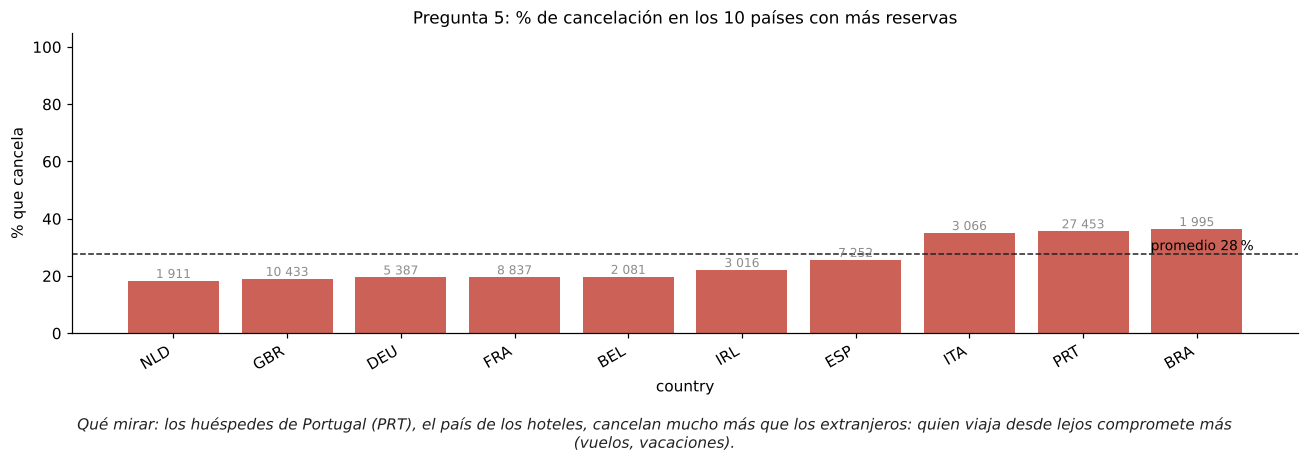

In [13]:
top_paises = eda["country"].value_counts().head(10).index
tasa_por_categoria(eda[eda["country"].isin(top_paises)], "country",
                   titulo="Pregunta 5: % de cancelación en los 10 países con más reservas",
                   leyenda="los huéspedes de Portugal (PRT), el país de los hoteles, cancelan mucho más que los extranjeros: "
                           "quien viaja desde lejos compromete más (vuelos, vacaciones).");

**Lectura.** Las reservas locales (Portugal) se cancelan mucho más. `country` tiene 177 valores distintos: no podemos convertirlo en 177 columnas. En la sección 6 nos quedamos con los 10 más frecuentes y agrupamos el resto.

### Pregunta 6 — La regla del 0 %: ¿hay alguna variable que separe *perfecto*?

🔍 **Predice:** de las reservas que pidieron **parqueadero**, ¿qué porcentaje cree que se canceló?

In [14]:
tabla = (eda.assign(pidio_parqueadero=eda["required_car_parking_spaces"] > 0)
            .groupby("pidio_parqueadero")["is_canceled"].agg(["mean", "size"]))
tabla.columns = ["% que cancela", "reservas"]
tabla.style.format({"% que cancela": "{:.1%}", "reservas": "{:,}"})

,% que cancela,reservas
pidio_parqueadero,,
False,30.0%,"80,083"
True,0.0%,"7,313"


**Lectura.** **Ninguna** de las más de 7 000 reservas que pidieron parqueadero se canceló: 0,0 %. En datos reales nada es perfecto, así que una variable que separa perfecto casi siempre es una variable que **se llenó después de conocer la *y***. Lo más probable es que el parqueadero se registre cuando el huésped **llega** al hotel. Si llegó, no canceló. Esto es exactamente lo que vimos en la Sesión 3, y lo resolvemos en la sección siguiente.

## 4. Columnas sospechosas de fuga 📦 E1

La pregunta de la Sesión 3, columna por columna: **¿esta información la tendría el hotel en el momento en que entra la reserva?** Si la respuesta es "no", la columna es del **futuro** y usarla es hacer trampa: el modelo se vería espectacular en el notebook y fracasaría con reservas nuevas.

| Columna | ¿Cuándo se conoce? | Decisión |
|---|---|---|
| `reservation_status` | Al final: dice *Canceled*, *Check-Out* o *No-Show*. **Es la *y* escrita de otra forma** | ❌ Fuera |
| `reservation_status_date` | Fecha del último estado (el día de la cancelación o de la salida) | ❌ Fuera |
| `assigned_room_type` | La habitación se asigna al llegar (a veces cambia por sobreventa) | ❌ Fuera |
| `booking_changes` | Según la documentación, cuenta los cambios **hasta la llegada o la cancelación** | ❌ Fuera (incluye información del futuro) |
| `required_car_parking_spaces` | La regla del 0 % (pregunta 6): casi seguro se registra al llegar | ❌ Fuera |
| `total_of_special_requests` | Puede crecer después de reservar, pero también se pide al reservar | ⚠️ Se queda, anotada como límite |
| `deposit_type` | Se define al reservar; tiene la rareza de la pregunta 4 | ⚠️ Se queda, anotada como límite |

En la sección 9 medimos **cuánto** inflarían los resultados estas columnas si las dejáramos. Por ahora quedan registradas como decisión.

> 📦 **En su proyecto (E1):** haga esta tabla para su dataset. No basta con decir "no hay fuga": muestre que revisó cada columna sospechosa y por qué la quitó o la dejó.

In [15]:
COLUMNAS_FUGA = ["reservation_status", "reservation_status_date", "assigned_room_type",
                 "booking_changes", "required_car_parking_spaces"]
print("Columnas del futuro que no van a entrar al modelo:", COLUMNAS_FUGA)

Columnas del futuro que no van a entrar al modelo: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces']


## 5. Limpieza 📦 E2

Cada decisión de limpieza se escribe con su **por qué**. La tabla resume lo que hace la celda siguiente.

| Problema | Qué se encontró | Decisión y por qué |
|---|---|---|
| Filas duplicadas | ~32 mil filas idénticas a otra | **Quitarlas.** No hay número de reserva para saber si son reservas distintas (por ejemplo, de un grupo) o copias. Si se quedan, una copia cae en entrenamiento y otra en prueba, y el modelo "acierta" por memoria (lo vemos a fondo en S10) |
| `children` vacío | 4 filas | Rellenar con 0: casi todas las reservas no traen niños |
| `meal = "Undefined"` | ~1 100 filas | Según la documentación, *Undefined* y *SC* significan lo mismo (sin comida): se unen |
| Reservas sin huéspedes | adultos + niños + bebés = 0 | Quitarlas: no es una reserva real |
| `adr` imposible | una tarifa negativa y una de 5 400 € la noche | Quitarlas: errores de digitación |
| `agent`, `company` vacíos | 14 % y 94 % de las filas | **No son errores**: vacío significa "sin agencia" o "sin empresa". Se convierten en una señal de sí/no (sección 6) |
| `country` vacío | ~450 filas | Se vuelve la categoría "Desconocido" (sección 6) |

In [16]:
df = df_original.copy()
n0 = len(df)

df = df.drop_duplicates()
print(f"1. Duplicados quitados: {n0 - len(df):,} → quedan {len(df):,}")

df["children"] = df["children"].fillna(0).astype(int)
df["meal"] = df["meal"].replace("Undefined", "SC")

sin_huespedes = (df["adults"] + df["children"] + df["babies"]) == 0
tarifa_rara = (df["adr"] < 0) | (df["adr"] > 1000)
df = df[~sin_huespedes & ~tarifa_rara].copy()
print(f"2. Sin huéspedes: {sin_huespedes.sum()} · tarifa imposible: {tarifa_rara.sum()} → quedan {len(df):,}")

print(f"\n% que cancela ANTES de quitar duplicados: {df_original['is_canceled'].mean():.1%}")
print(f"% que cancela DESPUÉS:                   {df['is_canceled'].mean():.1%}")

1. Duplicados quitados: 31,994 → quedan 87,396
2. Sin huéspedes: 166 · tarifa imposible: 2 → quedan 87,228

% que cancela ANTES de quitar duplicados: 37.0%
% que cancela DESPUÉS:                   27.5%


👀 **Mire** el último resultado: al quitar los duplicados, la cancelación baja del 37 % al 27,5 %. Los duplicados **no estaban repartidos al azar**: eran sobre todo reservas canceladas (muchas de grupo, con depósito no reembolsable). Una decisión de limpieza que parecía menor cambió la proporción de la *y* y, con ella, la línea base. Por eso cada decisión se escribe y se justifica.

## 6. *Feature engineering*: crear variables que el modelo no ve solo 📦 E2

*Feature engineering* es usar lo que **usted** sabe del negocio para construir columnas nuevas a partir de las que ya hay. Un árbol podría "descubrir" algunas de estas combinaciones por su cuenta, con mucho esfuerzo; una regresión logística no puede (solo suma columnas). Darle las variables listas ayuda a los dos.

| Variable nueva | Cómo se calcula | Por qué podría ayudar |
|---|---|---|
| `noches_totales` | noches de fin de semana + entre semana | La duración de la estadía, en un solo número |
| `huespedes`, `con_ninos` | adultos + niños + bebés · ¿hay niños o bebés? | Las familias planean distinto que quien viaja solo |
| `adr_por_persona` | tarifa por noche ÷ (adultos + niños) | El precio "real" que paga cada persona |
| `mes_llegada`, `dia_semana_llegada` | a partir de la fecha de llegada | La temporada (pregunta 3) y el día en que empieza el viaje |
| `con_agencia`, `con_empresa` | ¿`agent` / `company` tienen un valor? | Los vacíos que **sí** informan (sección 5) |
| `tasa_cancel_previa` | cancelaciones previas ÷ reservas previas del huésped | El historial del cliente, en una proporción |
| `pais` | los 10 países más frecuentes; el resto, "Otros"; vacío, "Desconocido" | 177 categorías no caben como columnas (pregunta 5) |

Todas usan información **de la misma reserva** y que se conoce al reservar. Ninguna mira la *y* ni usa datos de otras filas. Si una variable se calculara con promedios de todo el dataset (por ejemplo, "la tasa de cancelación del país"), habría que calcularla **solo con entrenamiento**: es el *target encoding* con fuga de la Sesión 3.

In [17]:
MES_NUM = {m: i for i, m in enumerate(MESES, start=1)}

df["mes_llegada"] = df["arrival_date_month"].map(MES_NUM)
fecha = pd.to_datetime(dict(year=df["arrival_date_year"], month=df["mes_llegada"], day=df["arrival_date_day_of_month"]))
df["dia_semana_llegada"] = fecha.dt.dayofweek                       # 0 = lunes … 6 = domingo
df["noches_totales"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["huespedes"] = df["adults"] + df["children"] + df["babies"]
df["con_ninos"] = ((df["children"] + df["babies"]) > 0).astype(int)
df["adr_por_persona"] = df["adr"] / (df["adults"] + df["children"]).clip(lower=1)
df["con_agencia"] = df["agent"].notna().astype(int)
df["con_empresa"] = df["company"].notna().astype(int)

previas = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
df["tasa_cancel_previa"] = np.where(previas > 0, df["previous_cancellations"] / previas.clip(lower=1), 0.0)

top10 = df["country"].value_counts().head(10).index
df["pais"] = np.select([df["country"].isin(top10), df["country"].isna()],
                       [df["country"], "Desconocido"], default="Otros")

df[["noches_totales", "huespedes", "con_ninos", "adr_por_persona", "mes_llegada",
    "dia_semana_llegada", "con_agencia", "con_empresa", "tasa_cancel_previa", "pais"]].head()

,noches_totales,huespedes,con_ninos,adr_por_persona,mes_llegada,dia_semana_llegada,con_agencia,con_empresa,tasa_cancel_previa,pais
0,0,2,0,0.0,7,2,0,0,0.0,PRT
1,0,2,0,0.0,7,2,0,0,0.0,PRT
2,1,1,0,75.0,7,2,0,0,0.0,GBR
3,1,1,0,75.0,7,2,1,0,0.0,GBR
4,2,2,0,49.0,7,2,1,0,0.0,GBR


¿Ayudan las variables nuevas? Una revisión rápida, antes de que las use cualquier modelo:

In [18]:
for col in ["con_ninos", "con_agencia", "con_empresa"]:
    t = df.groupby(col)["is_canceled"].mean()
    print(f"{col:12s} → cancela {t[0]:.0%} si es 0 · {t[1]:.0%} si es 1")

con_ninos    → cancela 27% si es 0 · 34% si es 1
con_agencia  → cancela 13% si es 0 · 30% si es 1
con_empresa  → cancela 29% si es 0 · 11% si es 1


**Lectura.** Las reservas que vienen por una empresa cancelan mucho menos (viajes de trabajo); las que vienen por agencia, más. Las variables nuevas traen información.

Ahora se arma la tabla final. Además de las columnas con fuga (sección 4), salen:

- `agent`, `company`, `country`: ya están resumidas en `con_agencia`, `con_empresa` y `pais`.
- `arrival_date_year`: el año sirve para describir el pasado, pero el modelo se va a usar con reservas de años que **no** están en los datos. Un modelo que aprende "en 2016 se cancelaba más" no sabe qué hacer con 2027.
- `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month`: quedan representadas por `mes_llegada` y `dia_semana_llegada`.

In [19]:
COLUMNAS_FUERA = ["agent", "company", "country", "arrival_date_year", "arrival_date_month",
                  "arrival_date_week_number", "arrival_date_day_of_month"]
Y = "is_canceled"

X = df.drop(columns=COLUMNAS_FUGA + COLUMNAS_FUERA + [Y])
y = df[Y]
num = X.select_dtypes("number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()
print(f"X: {X.shape[0]:,} filas × {X.shape[1]} columnas  ·  y: {y.mean():.1%} cancela")
print(f"\n{len(num)} numéricas:", num)
print(f"\n{len(cat)} categóricas:", cat)

X: 87,228 filas × 29 columnas  ·  y: 27.5% cancela

21 numéricas: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests', 'mes_llegada', 'dia_semana_llegada', 'noches_totales', 'huespedes', 'con_ninos', 'adr_por_persona', 'con_agencia', 'con_empresa', 'tasa_cancel_previa']

8 categóricas: ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'pais']


> 📦 **En su proyecto (E2):** documente su limpieza con una tabla *problema → decisión → por qué*, y su *feature engineering* con una tabla *variable nueva → cómo se calcula → por qué ayudaría*. Dos o tres variables bien pensadas valen más que veinte automáticas.

## 7. Partición: separar antes de que nada aprenda de los datos 📦 E2

Antes de escalar, imputar, balancear o entrenar, se aparta un pedazo de los datos que **nadie toca hasta el final**: la **prueba**. Es el examen final del modelo.

Además, del entrenamiento sacamos una **validación**: un examen de práctica para comparar modelos y decisiones en las secciones 9 a 12 sin gastar la prueba. En la sección 14 cambiamos la validación por algo mejor (validación cruzada).

```
 todos los datos ─┬─ 80 % entrenamiento completo ─┬─ 75 % entrenamiento  (aquí aprenden los modelos)
                  │                                └─ 25 % validación     (aquí los comparamos, secciones 9–12)
                  └─ 20 % prueba                   (bajo llave hasta la sección 16)
```

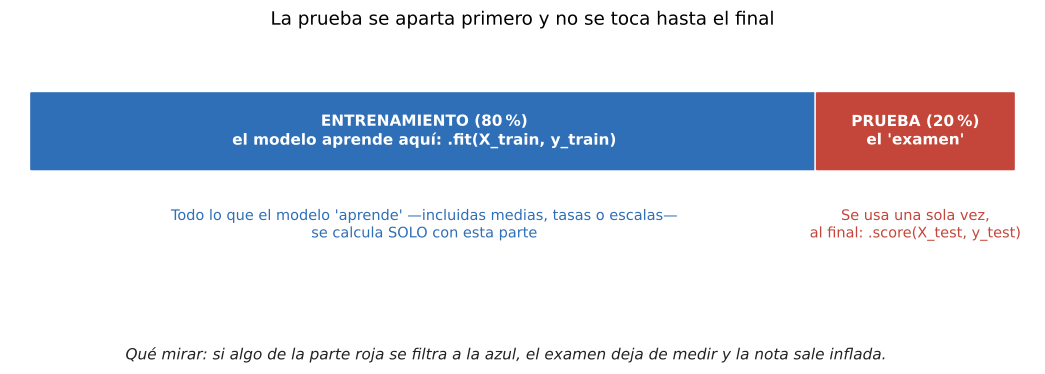

In [20]:
fg.split_esquema(0.8, titulo="La prueba se aparta primero y no se toca hasta el final");

🔍 **Predice:** usamos `stratify=y`. Si en todos los datos cancela el 27,5 %, ¿qué porcentaje cancela en entrenamiento, en validación y en prueba?

In [21]:
from sklearn.model_selection import train_test_split

X_ent_completo, X_prueba, y_ent_completo, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_ent, X_val, y_ent, y_val = train_test_split(
    X_ent_completo, y_ent_completo, test_size=0.25, stratify=y_ent_completo, random_state=SEMILLA)

for nombre, yy in [("entrenamiento", y_ent), ("validación", y_val), ("prueba", y_prueba)]:
    print(f"{nombre:14s} {len(yy):>7,} filas · cancela {yy.mean():.1%}")

entrenamiento   52,336 filas · cancela 27.5%
validación      17,446 filas · cancela 27.5%
prueba          17,446 filas · cancela 27.5%


**Lectura.** `stratify=y` reparte la *y* en la misma proporción en las tres partes. Sin estratificar, por puro azar, una parte podría quedar con más cancelaciones que otra y las comparaciones serían injustas.

> 📦 **En su proyecto (E2):** la partición va **antes** de cualquier paso que aprenda algo de los datos (imputar con la mediana, escalar, balancear, codificar). Si su dataset tiene fechas y el modelo se va a usar hacia el futuro, considere una partición temporal (sección 19).

## 8. Preprocesamiento dentro de un `Pipeline` 📦 E2

El preprocesamiento también **aprende** de los datos: la mediana para imputar, la media y la desviación para escalar, las categorías que existen. Todo eso se debe aprender **solo con entrenamiento**. La forma segura de garantizarlo es meter el preprocesamiento y el modelo en un mismo `Pipeline`: cuando se llama `.fit(X_ent, y_ent)`, todo aprende de entrenamiento; cuando se llama `.predict(X_val)`, todo solo **aplica** lo aprendido.

| Columnas | Pasos | Por qué |
|---|---|---|
| Numéricas sesgadas (`lead_time`, `adr`, `noches_totales`…) | imputar con la mediana → `log(1 + x)` → escalar | El logaritmo encoge la cola larga (pregunta 2): ayuda a los modelos que suman (logística) y a los que miden distancias (k-NN). A los árboles les da igual |
| Otras numéricas | imputar con la mediana → escalar | Escalar pone todo en unidades comparables (Sesión 5) |
| Categóricas | *one-hot*, agrupando en "infrecuente" las categorías con menos de 50 reservas | Los modelos necesitan números; agrupar evita columnas casi vacías y categorías nuevas que rompan el modelo |

Los árboles y los bosques no necesitan escalar ni logaritmos, pero no les hace daño. Usamos el mismo preprocesamiento para todos los modelos para que la comparación sea justa. Para dibujar el árbol (sección 11) usamos una versión sin escalar, que se lee en las unidades originales.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

def crear_preprocesador(num, cat, escalar=True):
    """Preprocesamiento del proyecto. Con escalar=False deja las numéricas en sus unidades (para leer un árbol)."""
    sesgadas = [c for c in ["lead_time", "days_in_waiting_list", "adr", "adr_por_persona", "noches_totales",
                            "previous_cancellations", "previous_bookings_not_canceled"] if c in num]
    resto = [c for c in num if c not in sesgadas]
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)
    if not escalar:
        return ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                                  ("cat", onehot, cat)], verbose_feature_names_out=False)
    return ColumnTransformer([
        ("sesgadas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                               ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                               ("escalar", StandardScaler())]), sesgadas),
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), resto),
        ("cat", onehot, cat),
    ], verbose_feature_names_out=False)

pre = crear_preprocesador(num, cat)
Z_ent = pre.fit_transform(X_ent)          # aprende SOLO de entrenamiento…
Z_val = pre.transform(X_val)              # …y a validación solo lo aplica
columnas_z = pre.get_feature_names_out()
print(f"Antes: {X_ent.shape[1]} columnas → después del preprocesamiento: {Z_ent.shape[1]} columnas")
print("Algunas columnas nuevas:", list(columnas_z[-8:]))

Antes: 29 columnas → después del preprocesamiento: 67 columnas
Algunas columnas nuevas: ['pais_ESP', 'pais_FRA', 'pais_GBR', 'pais_IRL', 'pais_ITA', 'pais_NLD', 'pais_Otros', 'pais_PRT']


**Lectura.** Las 29 columnas se volvieron unas 70: cada categoría es ahora una columna de 0/1. En adelante no vamos a llamar a `pre` por separado: va **dentro** de cada `Pipeline`, que es lo que lo hace seguro.

## 9. Línea base y métricas 📦 E2

La **línea base** es el modelo más tonto posible: siempre predice la clase más frecuente ("nadie cancela"). Cualquier modelo que valga la pena tiene que ganarle con claridad.

🔍 **Predice:** ¿qué *accuracy* tendrá un modelo que dice "nadie cancela", sin mirar ningún dato?

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

def evaluar(modelo, X_e, y_e, umbral=0.5):
    """Métricas de un modelo YA entrenado sobre un conjunto de evaluación."""
    proba = modelo.predict_proba(X_e)[:, 1]
    pred = (proba >= umbral).astype(int)
    return {"accuracy": accuracy_score(y_e, pred), "recall": recall_score(y_e, pred),
            "precisión": precision_score(y_e, pred, zero_division=0), "F1": f1_score(y_e, pred),
            "AUC": roc_auc_score(y_e, proba)}

resultados_val = {}      # aquí vamos guardando cada modelo: es la tabla de modelos del proyecto
linea_base = Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", DummyClassifier(strategy="most_frequent"))])
linea_base.fit(X_ent, y_ent)
resultados_val["línea base"] = evaluar(linea_base, X_val, y_val)
pd.DataFrame(resultados_val).T.round(3)

,accuracy,recall,precisión,F1,AUC
línea base,0.725,0.0,0.0,0.0,0.5


**Lectura.** ¡72,5 % de *accuracy* sin aprender nada! Y un *recall* de 0: no encuentra **ni una** cancelación. Cuando una clase domina, el *accuracy* premia al modelo que la repite siempre. Por eso, en este proyecto, la métrica para comparar es el **AUC** (0,5 = adivinar al azar; 1 = ordenar perfecto) y para decidir usamos **recall, precisión y F1**.

### 📘 Para entender — las cinco métricas en una tabla

| Métrica | Pregunta que responde | En este proyecto |
|---|---|---|
| *Accuracy* | De todas las reservas, ¿cuántas acerté? | Engaña cuando una clase domina |
| *Recall* | De las que **sí** cancelaron, ¿cuántas encontré? | Habitaciones vacías que el hotel logra anticipar |
| Precisión | De las que **marqué** como "va a cancelar", ¿cuántas cancelaron? | Cuántas veces se sobrevende sin necesidad |
| F1 | Promedio (armónico) de recall y precisión | Un solo número cuando importan las dos |
| AUC | Si tomo una reserva que canceló y una que no, ¿con qué probabilidad el modelo le da más riesgo a la que canceló? | Compara modelos **sin** haber elegido umbral |

### 💥 ¿Y si hubiéramos dejado las columnas del futuro?

En la sección 4 quitamos cinco columnas "por precaución". ¿Cuánto cambiaba eso de verdad? Entrenamos el **mismo árbol** en tres escenarios y lo medimos en validación.

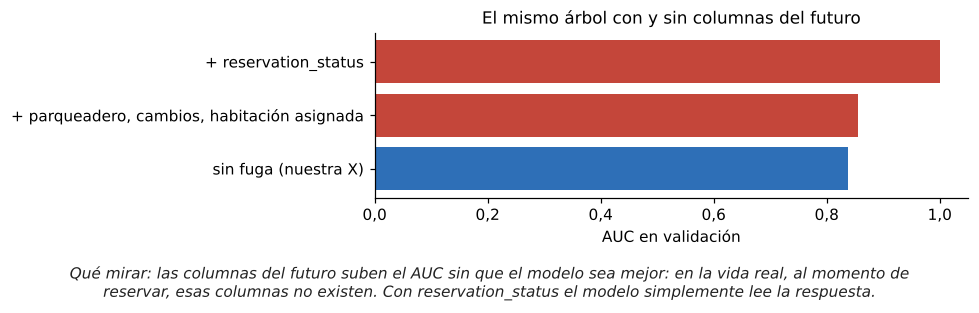

In [24]:
from sklearn.tree import DecisionTreeClassifier

def arbol_con(columnas_extra):
    """Mismo árbol y mismas filas, agregando columnas del futuro a X."""
    Xf = df[X.columns.tolist() + columnas_extra]
    n_f = Xf.select_dtypes("number").columns.tolist(); c_f = Xf.select_dtypes(exclude="number").columns.tolist()
    m = Pipeline([("pre", crear_preprocesador(n_f, c_f)),
                  ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA))])
    m.fit(Xf.loc[X_ent.index], y_ent)
    return roc_auc_score(y_val, m.predict_proba(Xf.loc[X_val.index])[:, 1])

escenarios = {
    "sin fuga (nuestra X)": arbol_con([]),
    "+ parqueadero, cambios, habitación asignada": arbol_con(["required_car_parking_spaces", "booking_changes", "assigned_room_type"]),
    "+ reservation_status": arbol_con(["reservation_status"]),
}
barras_horizontales(pd.Series(escenarios), "El mismo árbol con y sin columnas del futuro", "AUC en validación",
                    "las columnas del futuro suben el AUC sin que el modelo sea mejor: en la vida real, al momento de reservar, "
                    "esas columnas no existen. Con reservation_status el modelo simplemente lee la respuesta.",
                    color=[fg.AZUL, fg.ROJO, fg.ROJO]);

**Lectura.** Con las columnas sutiles, el AUC sube un par de puntos: poco, y justamente por eso es peligroso, porque una mejora pequeña no despierta sospechas. Con `reservation_status`, el modelo llega a la perfección porque **lee la respuesta**. Ninguno de esos dos modelos serviría en la recepción del hotel. Muchos notebooks de Kaggle con este dataset reportan resultados espectaculares precisamente por no quitar estas columnas.

## 10. Desbalance de clases 📦 E2

Solo el 27,5 % de las reservas cancela. No es un desbalance extremo (como un fraude de 1 en 1 000), pero sí suficiente para que un modelo, con el umbral por defecto de 0,5, se incline a decir "no cancela". Hay tres formas comunes de compensarlo. Las comparamos con el mismo modelo, una regresión logística:

1. **No hacer nada** (umbral 0,5).
2. **`class_weight="balanced"`**: en el entrenamiento, cada error en la clase minoritaria cuenta más.
3. **SMOTE**: crea reservas canceladas *sintéticas* (interpolando entre vecinos reales) hasta igualar las clases. Viene de la librería `imbalanced-learn`.

🔍 **Predice:** ¿cuál de las tres opciones cree que tendrá el AUC más alto?

In [25]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as PipelineImb      # Pipeline que acepta pasos de remuestreo
from imblearn.over_sampling import SMOTE

opciones = {
    "sin ajuste": Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", LogisticRegression(max_iter=2000))]),
    "class_weight": Pipeline([("pre", crear_preprocesador(num, cat)),
                              ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE": PipelineImb([("pre", crear_preprocesador(num, cat)), ("smote", SMOTE(random_state=SEMILLA)),
                          ("modelo", LogisticRegression(max_iter=2000))]),
}
tabla_desbalance = {n: evaluar(m.fit(X_ent, y_ent), X_val, y_val) for n, m in opciones.items()}
tabla_desbalance["sin ajuste, umbral 0,3"] = evaluar(opciones["sin ajuste"], X_val, y_val, umbral=0.3)
pd.DataFrame(tabla_desbalance).T.round(3)

,accuracy,recall,precisión,F1,AUC
sin ajuste,0.789,0.441,0.680,0.535,0.82
class_weight,0.734,0.754,0.512,0.610,0.82
SMOTE,0.738,0.744,0.517,0.610,0.82
"sin ajuste, umbral 0,3",0.749,0.719,0.533,0.612,0.82


**Lectura.** Tres cosas para llevarse:

- El **AUC prácticamente no cambia**. Balancear no hace que el modelo *ordene* mejor las reservas; lo que cambia es **dónde corta**.
- `class_weight` y SMOTE suben mucho el *recall* a cambio de precisión. Es casi lo mismo que conseguimos sin balancear, solo **bajando el umbral** (última fila).
- Por eso, en la práctica: compare modelos con AUC y decida el umbral pensando en el negocio (sección 16). `class_weight` es la opción más simple; SMOTE, la más costosa, y casi nunca gana por mucho.

### ❌ Cómo NO balancear

El error más común en los notebooks de Kaggle es aplicar SMOTE **antes** de partir los datos:

```python
# ❌ MAL: las reservas sintéticas se fabrican mezclando filas que después caen en prueba
X_bal, y_bal = SMOTE().fit_resample(X, y)
X_ent, X_prueba, y_ent, y_prueba = train_test_split(X_bal, y_bal)

# ✅ BIEN: SMOTE dentro de un Pipeline de imblearn; solo actúa al entrenar, solo con entrenamiento
modelo = PipelineImb([("pre", preprocesador), ("smote", SMOTE()), ("modelo", LogisticRegression())])
modelo.fit(X_ent, y_ent)
```

En el primer caso, la prueba queda llena de filas "hijas" de filas de entrenamiento y la prueba se balancea (deja de parecerse a la realidad). Es fuga, igual que en la Sesión 3.

> 📦 **En su proyecto (E2):** si su *y* es una clasificación desbalanceada, reporte la proporción, compare al menos "sin ajuste" contra `class_weight`, y diga qué métrica usa y por qué. Si es una regresión, esta sección no aplica.

## 11. Modelos 📦 E2 · E4

Ahora sí, los modelos. Para cada uno: **(A)** cómo funciona por dentro, con una figura sobre datos sintéticos de dos variables; el entrenamiento; **(B)** qué aprendió con nuestros datos, y **(C)** qué pasa cuando cambia su perilla principal.

Los dos primeros (árbol y regresión logística) van con más detalle. Los otros tres son **vitrina**: una figura, una ficha y su resultado. Los vemos a fondo en la sesión que indica cada uno.

### 11.1 Árbol de decisión (Sesión 1)

**(A) Cómo funciona.** El árbol hace preguntas de sí/no ("¿la anticipación es mayor que 100 días?") y en cada paso elige la pregunta que mejor separa las clases. Cada pregunta corta el plano con una línea recta.

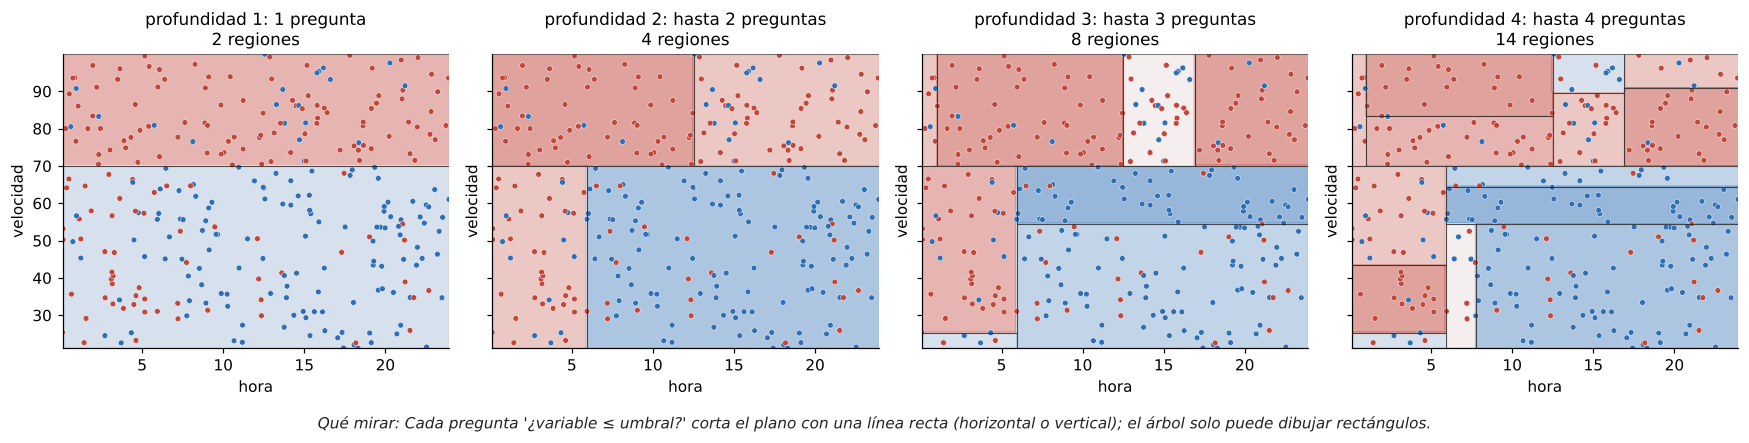

In [26]:
fg.arbol_paso_a_paso();

| Dentro del `.fit()` | Árbol de decisión |
|---|---|
| Qué aprende | Una secuencia de preguntas "¿variable ≤ umbral?" y una predicción en cada hoja |
| Qué minimiza | La impureza de Gini en cada corte (qué tan mezcladas quedan las clases) |
| Cómo optimiza | Búsqueda exhaustiva y voraz: prueba todos los cortes posibles y se queda con el mejor, nivel por nivel. Sin gradiente ni tasa de aprendizaje |
| Perilla principal | `max_depth` (cuántas preguntas seguidas) y `min_samples_leaf` (cuántos casos mínimo por hoja) |

In [27]:
arbol = Pipeline([("pre", crear_preprocesador(num, cat)),
                  ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA))])
arbol.fit(X_ent, y_ent)
resultados_val["árbol"] = evaluar(arbol, X_val, y_val)
pd.DataFrame(resultados_val).T.round(3)

,accuracy,recall,precisión,F1,AUC
línea base,0.725,0.00,0.000,0.000,0.500
árbol,0.799,0.56,0.658,0.605,0.838


**(B) Qué aprendió.** Dibujamos los dos primeros niveles de un árbol entrenado **sin escalar**, para que los umbrales se lean en días, euros o reservas.

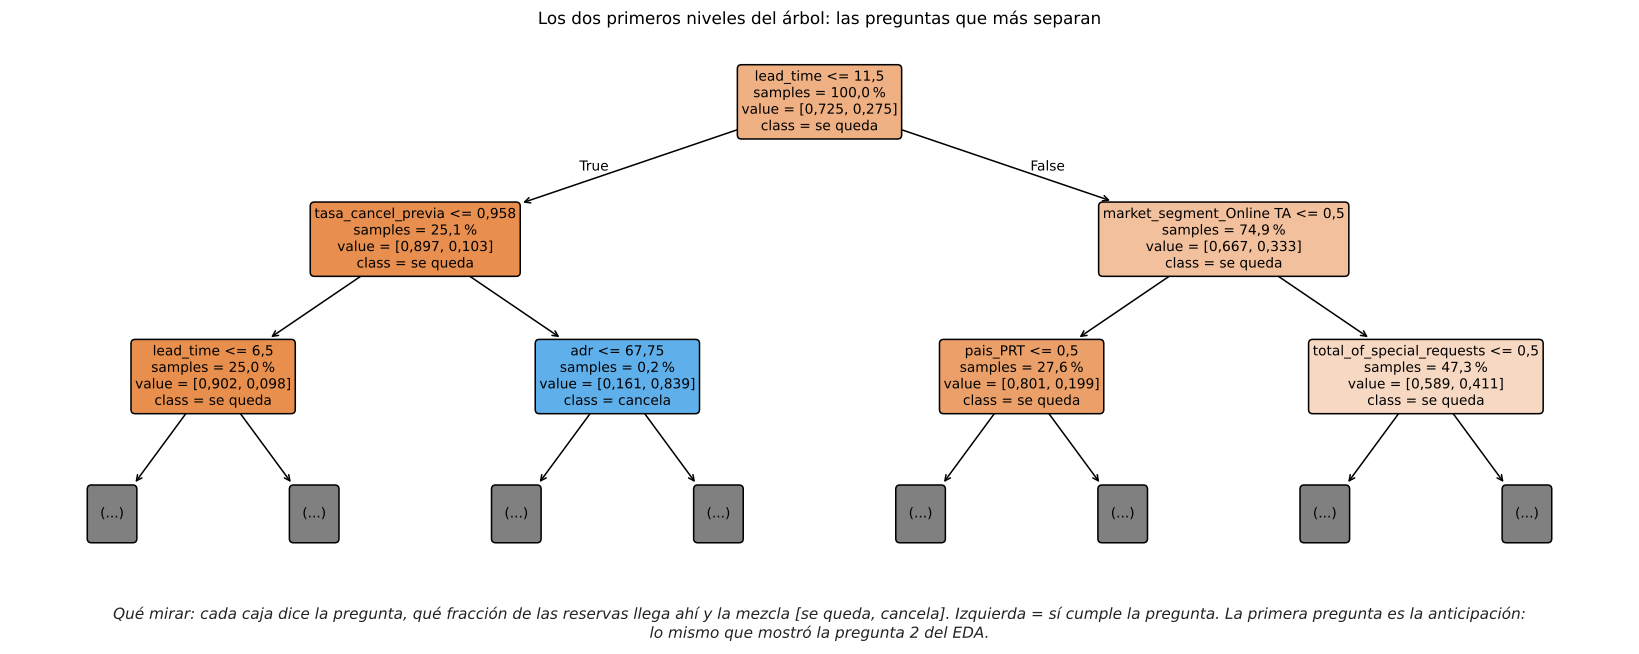

In [28]:
from sklearn.tree import plot_tree

pre_sin_escalar = crear_preprocesador(num, cat, escalar=False)
arbol_legible = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA)
arbol_legible.fit(pre_sin_escalar.fit_transform(X_ent), y_ent)

fig, ax = plt.subplots(figsize=(15, 5.5))
plot_tree(arbol_legible, max_depth=2, feature_names=pre_sin_escalar.get_feature_names_out(), class_names=["se queda", "cancela"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Los dos primeros niveles del árbol: las preguntas que más separan"); fig.tight_layout()
fg._leyenda(fig, "cada caja dice la pregunta, qué fracción de las reservas llega ahí y la mezcla [se queda, cancela]. "
                 "Izquierda = sí cumple la pregunta. La primera pregunta es la anticipación: lo mismo que mostró la pregunta 2 del EDA.");

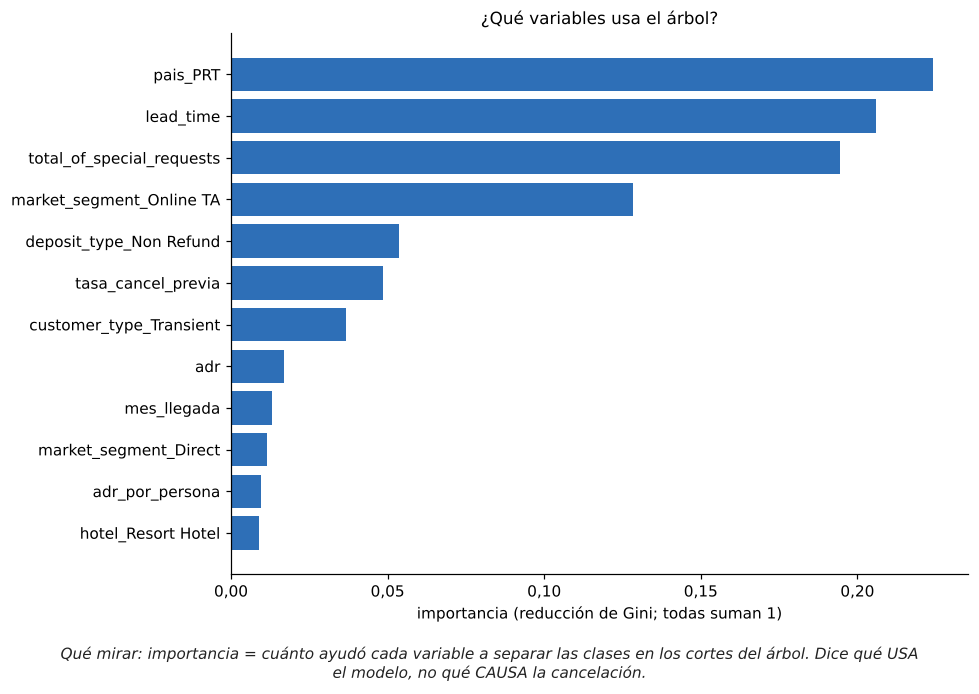

In [29]:
imp_arbol = pd.Series(arbol.named_steps["modelo"].feature_importances_, index=columnas_z).sort_values().tail(12)
barras_horizontales(imp_arbol, "¿Qué variables usa el árbol?", "importancia (reducción de Gini; todas suman 1)",
                    "importancia = cuánto ayudó cada variable a separar las clases en los cortes del árbol. Dice qué USA el modelo, "
                    "no qué CAUSA la cancelación.", color=fg.AZUL);

**(C) La perilla `max_depth`.** ¿Qué pasa al dejar crecer el árbol? Para que corra rápido usamos 20 000 reservas de entrenamiento. La figura muestra también un **bosque** (sección 11.3), como adelanto.

🔍 **Predice:** si el árbol crece sin límite, ¿el AUC en validación sube, se queda igual o baja?

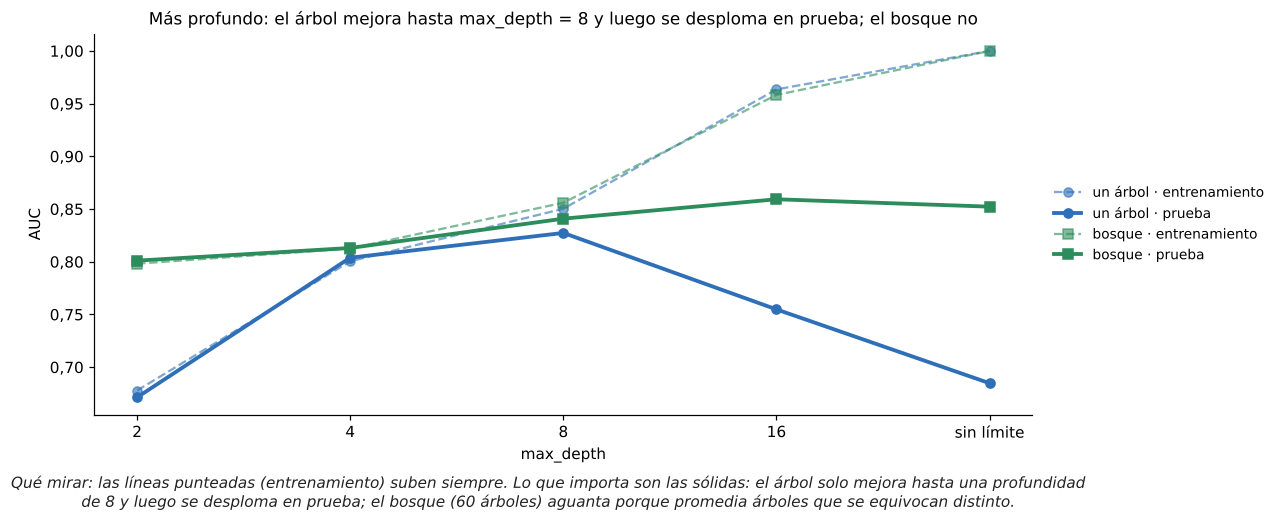

In [30]:
idx = X_ent.sample(20_000, random_state=SEMILLA).index
fg.complejidad_auc(pre_sin_escalar.transform(X_ent.loc[idx]), y_ent.loc[idx],
                   pre_sin_escalar.transform(X_val), y_val, profundidades=(2, 4, 8, 16, None), n_arboles=60);

**Lectura.** (En esta figura, "prueba" es nuestra validación.) En entrenamiento (punteado), más profundidad siempre "mejora". En validación (sólido), el árbol mejora hasta cierta profundidad y después empieza a **memorizar** (sobreajuste, Sesión 3). El bosque aguanta mucho mejor la profundidad: promedia árboles que se equivocan distinto.

### 11.2 Regresión logística (Sesión 5)

**(A) Cómo funciona.** Hace lo mismo que una regresión lineal (Sesión 4): suma las variables, cada una con un peso. Después pasa esa suma por una curva en forma de S, la **sigmoide**, que la convierte en una probabilidad entre 0 y 1.

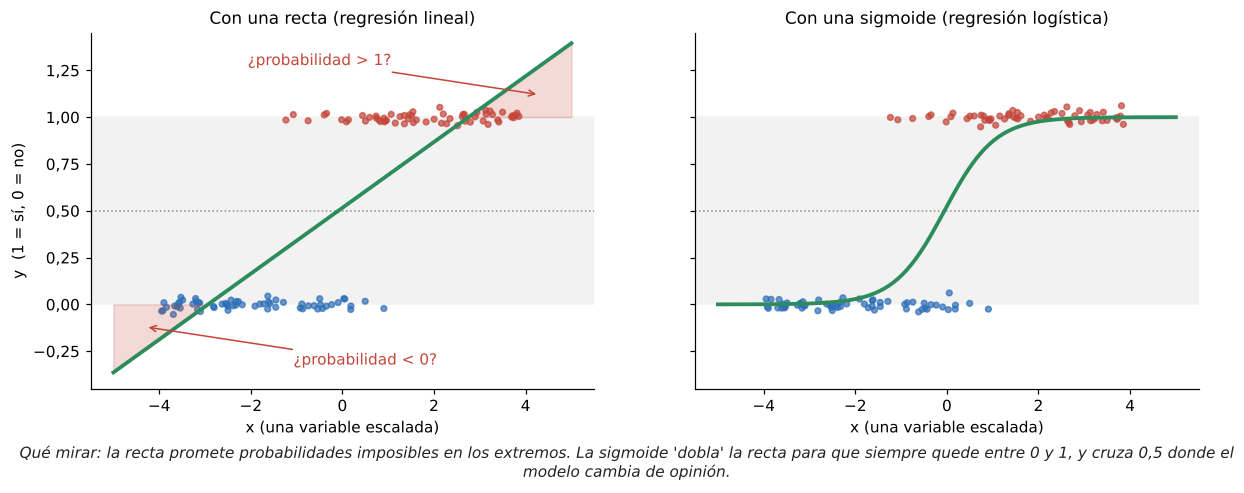

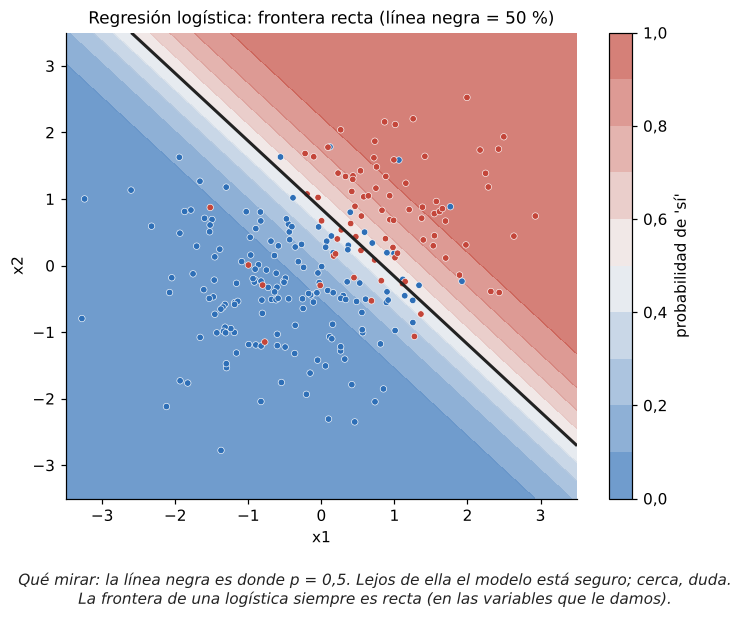

In [31]:
fg.sigmoide_vs_recta();
fg.frontera_logistica_2d();

### 📐 Fundamento

$$z = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p \qquad\qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

- $z$ es la suma ponderada (puede ser cualquier número); $p$, la probabilidad de cancelar.
- Un coeficiente $\beta_j$ positivo empuja hacia "cancela"; uno negativo, hacia "se queda". Como las variables están escaladas, los coeficientes se pueden comparar entre sí.

<details><summary><b>Para quien quiera más:</b> qué minimiza</summary>

La logística minimiza la **pérdida logarítmica** (*log loss*, o entropía cruzada):
$$\text{pérdida} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big] + \frac{1}{C}\,\lVert\beta\rVert^2$$
El primer término castiga duro decir "1 % de cancelar" a una reserva que canceló. El segundo es la **regularización** (como Ridge en la Sesión 4): `C` grande = poca regularización. No hay fórmula cerrada: scikit-learn la resuelve con un método iterativo de la familia del descenso de gradiente (`lbfgs`).
</details>

| Dentro del `.fit()` | Regresión logística |
|---|---|
| Qué aprende | Un coeficiente por columna y un intercepto |
| Qué minimiza | La pérdida logarítmica + una penalización a los coeficientes grandes |
| Cómo optimiza | Iterativo (`lbfgs`, pariente del descenso de gradiente). Por eso necesita `max_iter` y variables escaladas |
| Perilla principal | `C` (inverso de la regularización) y `class_weight` |

In [32]:
logistica = Pipeline([("pre", crear_preprocesador(num, cat)),
                      ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))])
logistica.fit(X_ent, y_ent)
resultados_val["regresión logística"] = evaluar(logistica, X_val, y_val)
pd.DataFrame(resultados_val).T.round(3)

,accuracy,recall,precisión,F1,AUC
línea base,0.725,0.000,0.000,0.000,0.500
árbol,0.799,0.560,0.658,0.605,0.838
regresión logística,0.734,0.754,0.512,0.610,0.820


**(B) Qué aprendió.** Los coeficientes con más peso, hacia un lado y hacia el otro:

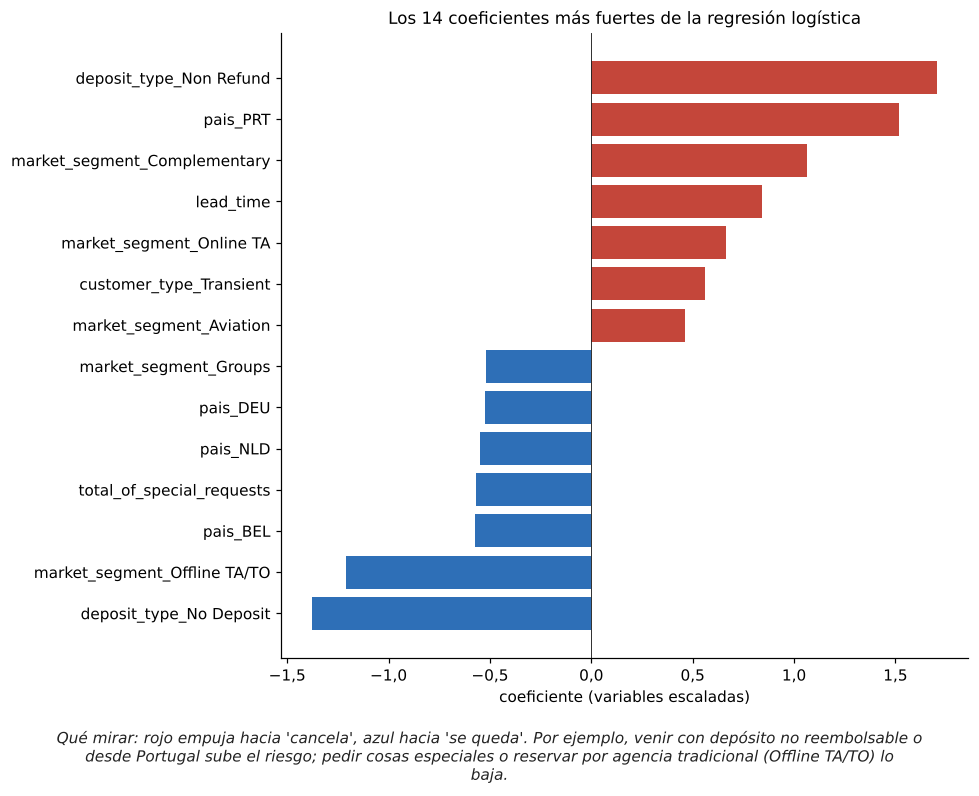

In [33]:
coef = pd.Series(logistica.named_steps["modelo"].coef_[0], index=columnas_z)
principales = coef.reindex(coef.abs().sort_values(ascending=False).index).head(14)
barras_horizontales(principales, "Los 14 coeficientes más fuertes de la regresión logística", "coeficiente (variables escaladas)",
                    "rojo empuja hacia 'cancela', azul hacia 'se queda'. Por ejemplo, venir con depósito no reembolsable o desde "
                    "Portugal sube el riesgo; pedir cosas especiales o reservar por agencia tradicional (Offline TA/TO) lo baja.");

**Una fila entra, una predicción sale.** Así decide la logística para **una** reserva de validación: suma las contribuciones y la sigmoide las convierte en probabilidad.

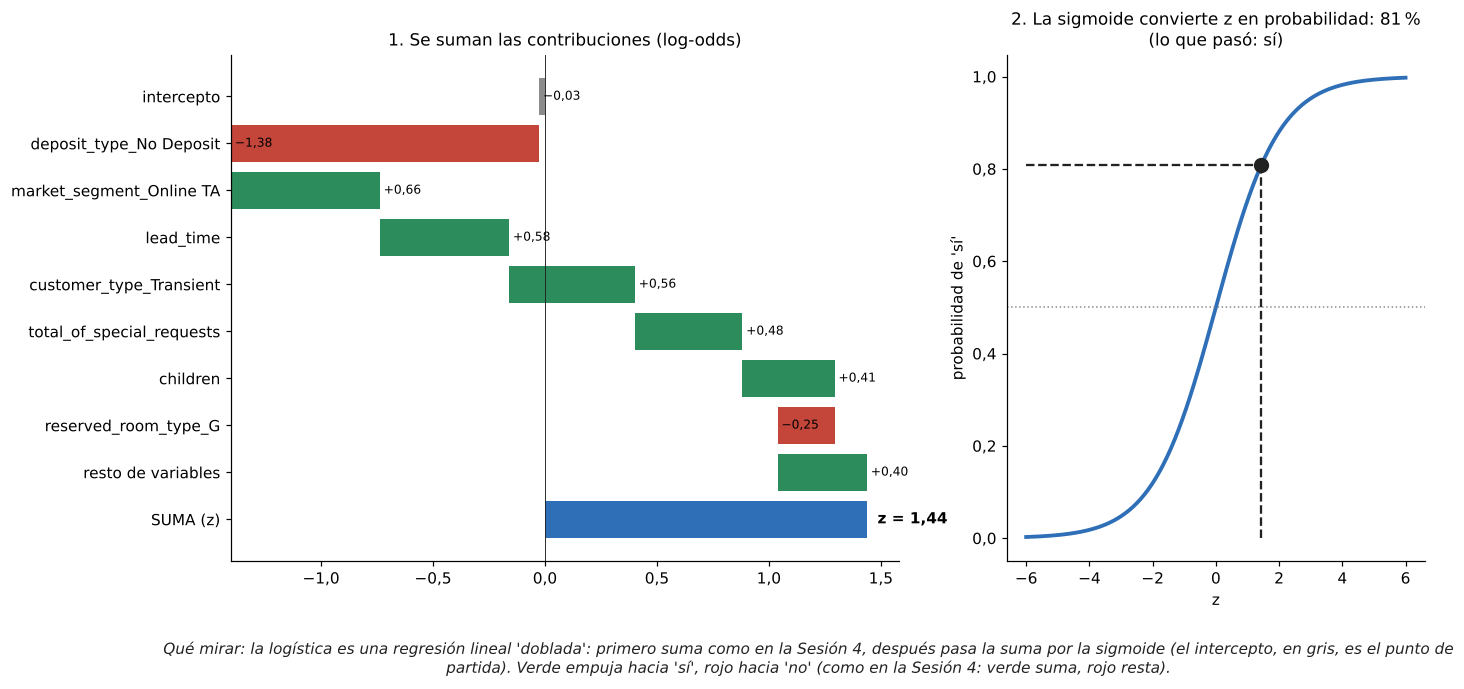

In [34]:
proba_val = logistica.predict_proba(X_val)[:, 1]
i = int(np.argmax((proba_val > 0.75) & (proba_val < 0.9) & (y_val.values == 1)))   # una reserva de riesgo alto que sí canceló
fila_z = logistica.named_steps["pre"].transform(X_val.iloc[[i]])[0]
fg.logistica_una_fila(logistica.named_steps["modelo"], fila_z, columnas_z, real=int(y_val.iloc[i]));

**(C) La perilla `C`.** Con `C` muy pequeño, la regularización aplasta todos los coeficientes hacia 0 y el modelo casi no aprende. Con `C` grande, cada variable pesa lo que quiera.

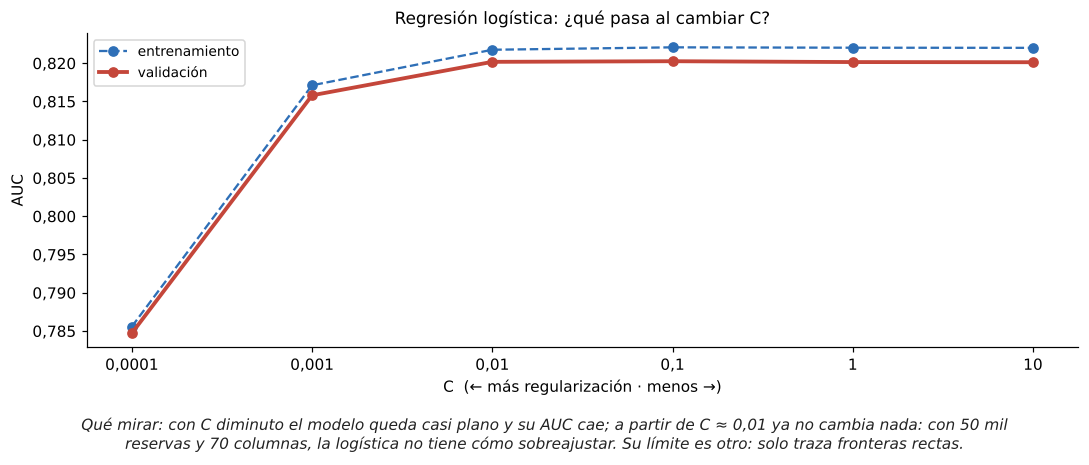

In [35]:
Cs = [0.0001, 0.001, 0.01, 0.1, 1, 10]
auc_ent, auc_val = [], []
for C in Cs:
    m = Pipeline([("pre", crear_preprocesador(num, cat)),
                  ("modelo", LogisticRegression(C=C, max_iter=2000, class_weight="balanced"))]).fit(X_ent, y_ent)
    auc_ent.append(roc_auc_score(y_ent, m.predict_proba(X_ent)[:, 1]))
    auc_val.append(roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(range(len(Cs)), auc_ent, "o--", color=fg.AZUL, label="entrenamiento")
ax.plot(range(len(Cs)), auc_val, "o-", color=fg.ROJO, lw=2.5, label="validación")
ax.set_xticks(range(len(Cs))); ax.set_xticklabels([str(c) for c in Cs]); ax.set_xlabel("C  (← más regularización · menos →)")
ax.set_ylabel("AUC"); ax.legend(); ax.set_title("Regresión logística: ¿qué pasa al cambiar C?"); fig.tight_layout()
fg._leyenda(fig, "con C diminuto el modelo queda casi plano y su AUC cae; a partir de C ≈ 0,01 ya no cambia nada: con 50 mil reservas "
                 "y 70 columnas, la logística no tiene cómo sobreajustar. Su límite es otro: solo traza fronteras rectas.");

### 11.3 Vitrina: tres modelos más

Estos tres modelos los vemos a fondo más adelante. Aquí basta con la intuición y con ver cómo les va.

#### k vecinos más cercanos, k-NN (Sesión 5)

Para una reserva nueva, busca las *k* reservas de entrenamiento más parecidas y vota. No aprende ninguna fórmula: **guarda los datos** y compara.

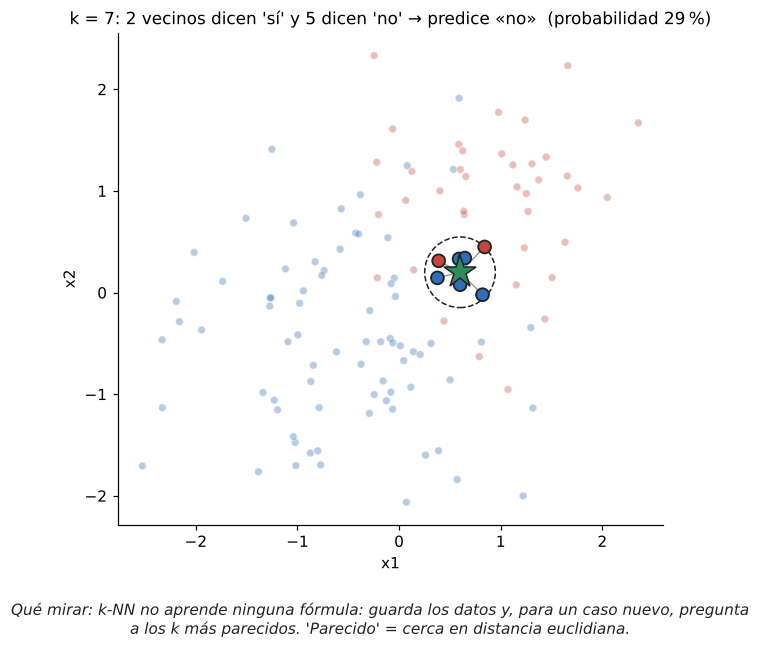

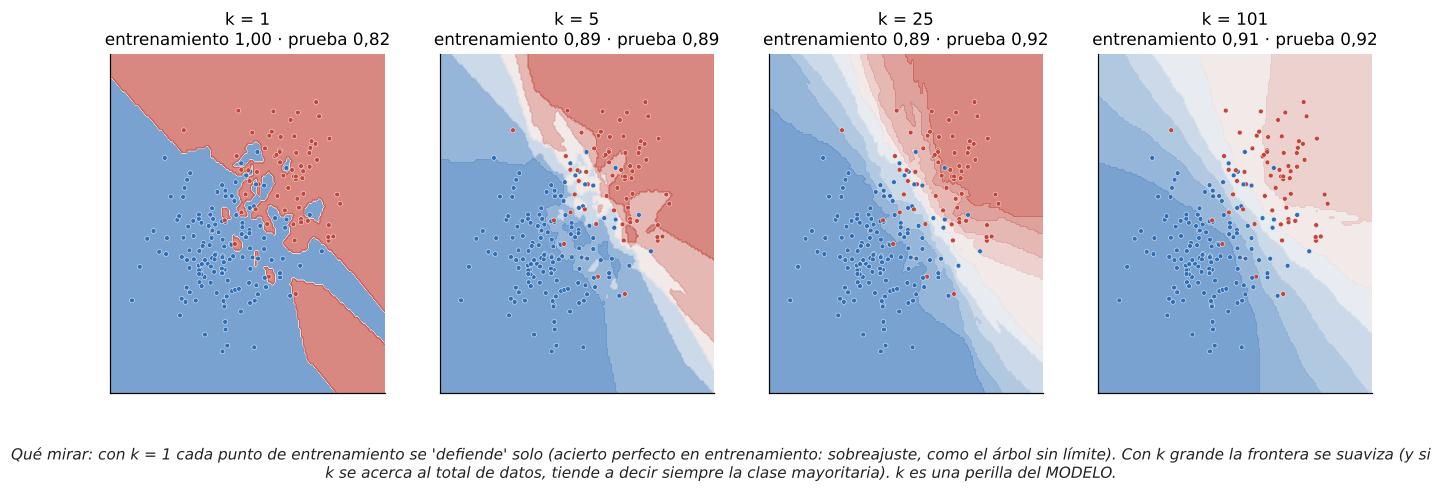

In [36]:
fg.knn_vecinos();
fg.knn_k_efecto();

| Dentro del `.fit()` | k-NN |
|---|---|
| Qué aprende | Nada: guarda el entrenamiento. Todo el trabajo ocurre al predecir |
| Qué minimiza | No optimiza una pérdida: decide por mayoría entre los vecinos |
| Perilla principal | `n_neighbors` (k). Pequeño = frontera nerviosa (memoriza); grande = suave |
| Cuidado | Mide distancias: **sin escalar no funciona**. Y es lento con muchos datos (compara con todos) |

In [37]:
from sklearn.neighbors import KNeighborsClassifier
knn = Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", KNeighborsClassifier(n_neighbors=25))])
knn.fit(X_ent, y_ent)
resultados_val["k-NN (k = 25)"] = evaluar(knn, X_val, y_val)

#### Bosque aleatorio (Sesión 6)

Entrena **muchos árboles**, cada uno con una muestra distinta de filas y de columnas, y promedia lo que dicen. Cada árbol se equivoca a su manera; el promedio se equivoca menos.

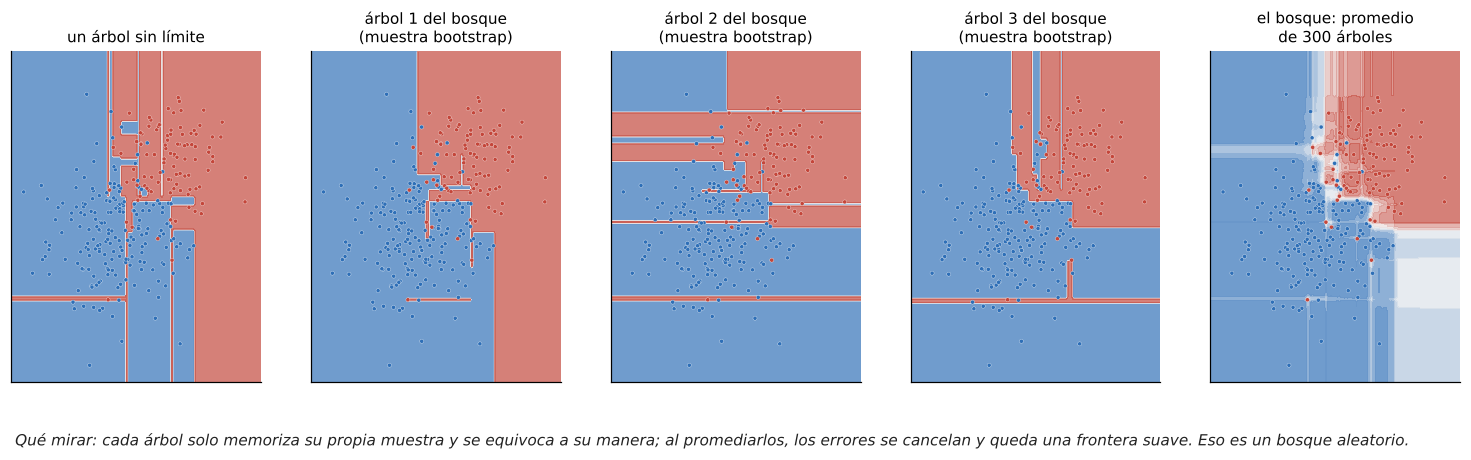

In [38]:
fg.arbol_vs_bosque();

| Dentro del `.fit()` | Bosque aleatorio |
|---|---|
| Qué aprende | Cientos de árboles independientes |
| Qué minimiza | Cada árbol minimiza Gini en su propia muestra (*bootstrap*) |
| Cómo optimiza | Igual que el árbol, pero en paralelo; el azar (filas y columnas) hace que los árboles sean distintos |
| Perilla principal | `n_estimators` (cuántos árboles), `max_depth`, `min_samples_leaf`, `max_features` |

In [39]:
from sklearn.ensemble import RandomForestClassifier
bosque = Pipeline([("pre", crear_preprocesador(num, cat)),
                   ("modelo", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEMILLA))])
bosque.fit(X_ent, y_ent)
resultados_val["bosque aleatorio"] = evaluar(bosque, X_val, y_val)

#### Gradient boosting (Sesión 11)

También usa muchos árboles, pero **en fila**: cada árbol nuevo se entrena para corregir los errores que dejaron los anteriores. Es la familia de XGBoost, LightGBM y CatBoost, que domina las competencias de Kaggle con datos en tabla.

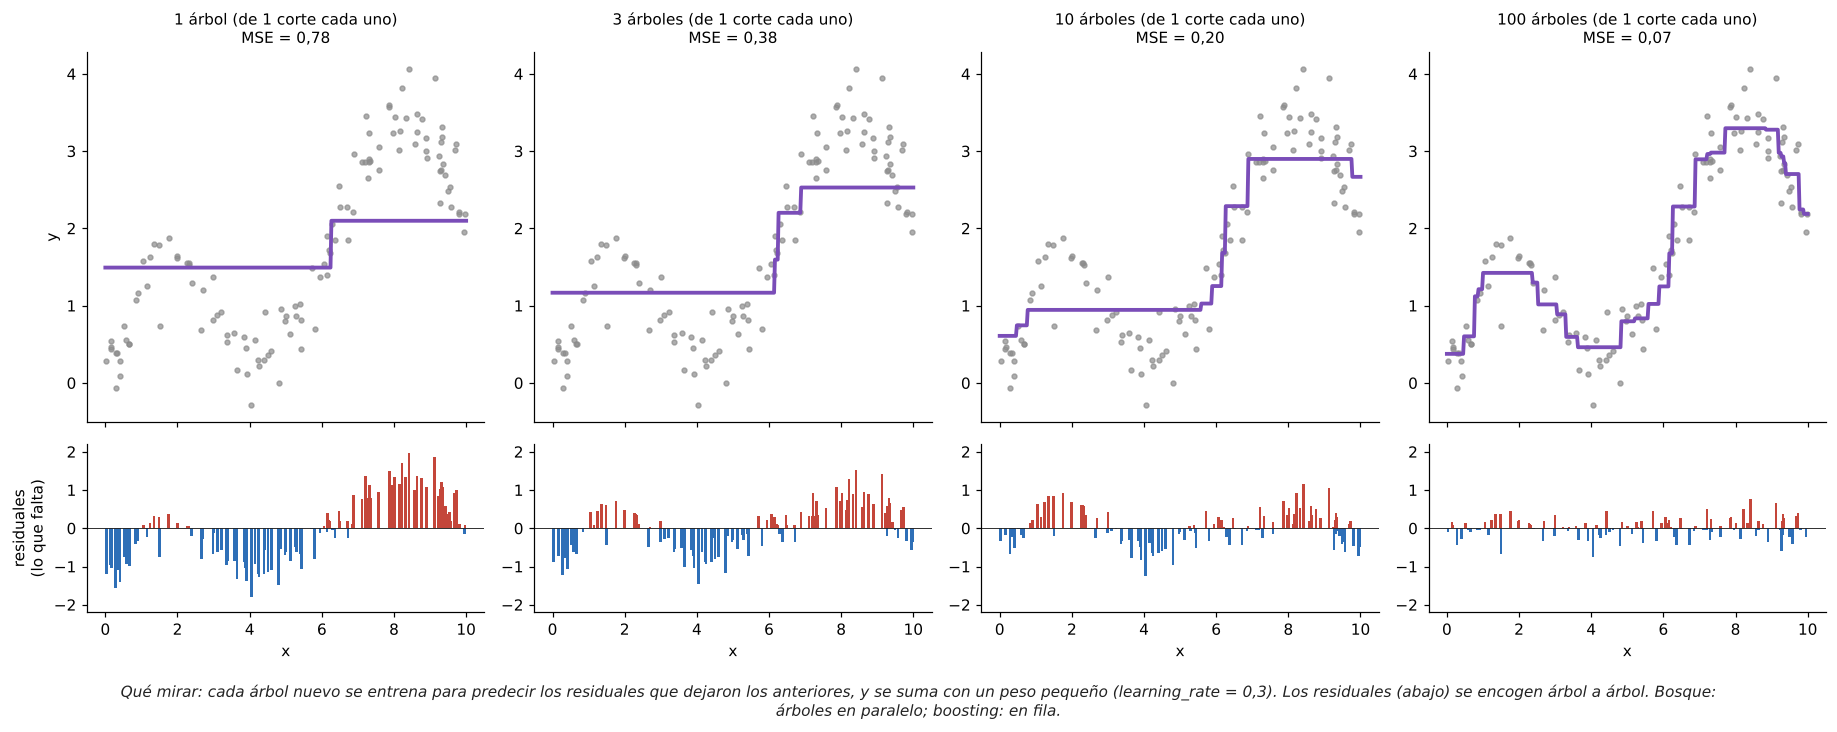

In [40]:
fg.boosting_paso_a_paso();

| Dentro del `.fit()` | Gradient boosting |
|---|---|
| Qué aprende | Una suma de árboles pequeños, cada uno con un peso |
| Qué minimiza | La pérdida logarítmica (como la logística), árbol por árbol |
| Cómo optimiza | Descenso de gradiente, pero en vez de mover coeficientes **agrega un árbol** en la dirección que más baja la pérdida |
| Perilla principal | `learning_rate` (cuánto corrige cada árbol), `max_iter` (cuántos árboles), `max_leaf_nodes` / `max_depth` |

Usamos `HistGradientBoostingClassifier`, la versión rápida de scikit-learn.

In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier
boosting = Pipeline([("pre", crear_preprocesador(num, cat)),
                     ("modelo", HistGradientBoostingClassifier(random_state=SEMILLA))])
boosting.fit(X_ent, y_ent)
resultados_val["gradient boosting"] = evaluar(boosting, X_val, y_val)

### La tabla de modelos (en validación)

🔍 **Predice:** ¿qué modelo cree que tendrá el AUC más alto? ¿Cuánto le ganará al árbol solo?

In [42]:
tabla_val = pd.DataFrame(resultados_val).T.round(3)
tabla_val.style.format("{:.3f}").background_gradient(subset=["AUC"], cmap="Greens")

,accuracy,recall,precisión,F1,AUC
línea base,0.725,0.000,0.000,0.000,0.500
árbol,0.799,0.560,0.658,0.605,0.838
regresión logística,0.734,0.754,0.512,0.610,0.820
k-NN (k = 25),0.797,0.488,0.684,0.569,0.824
bosque aleatorio,0.824,0.552,0.741,0.633,0.874
gradient boosting,0.818,0.562,0.717,0.630,0.868


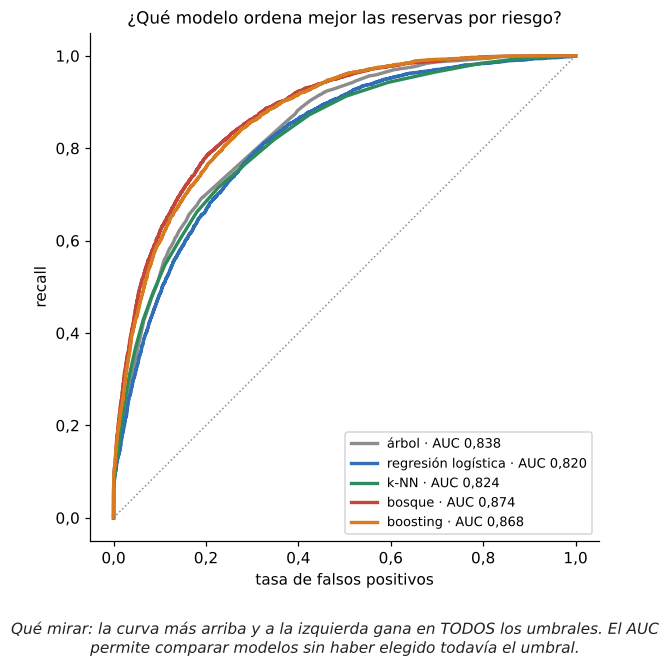

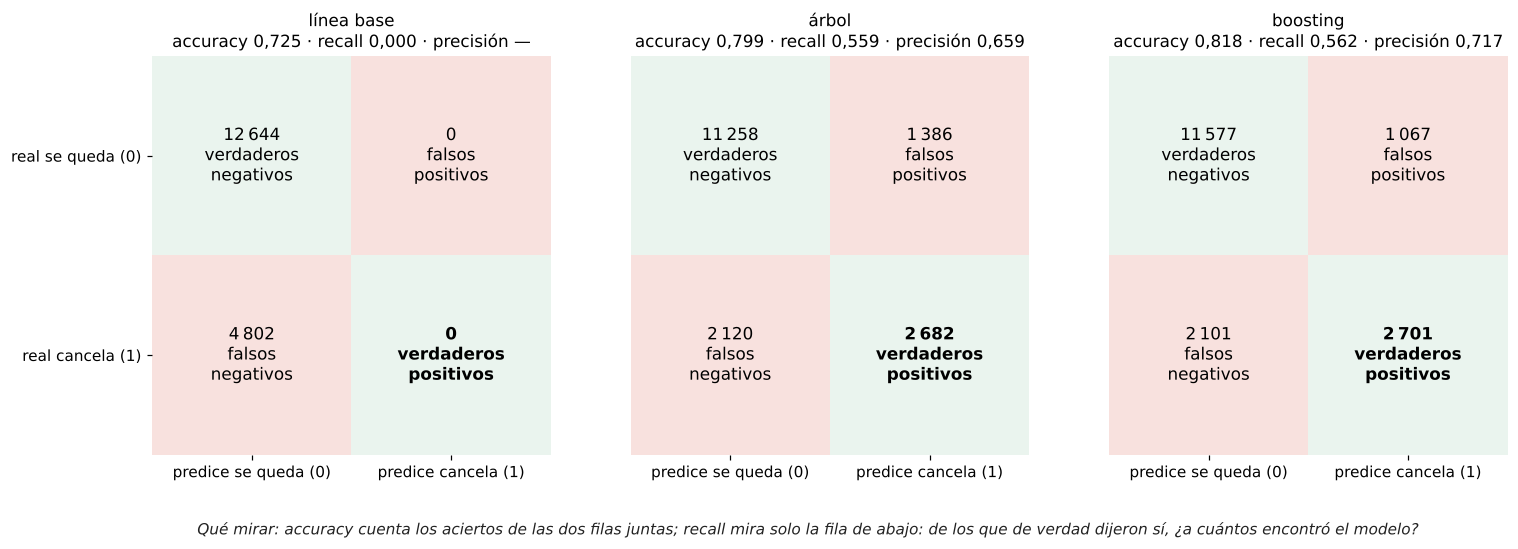

In [43]:
modelos_val = {"árbol": arbol, "regresión logística": logistica, "k-NN": knn, "bosque": bosque, "boosting": boosting}
fg.curvas_roc({n: m.predict_proba(X_val)[:, 1] for n, m in modelos_val.items()}, y_val,
              titulo="¿Qué modelo ordena mejor las reservas por riesgo?");
fg.matrices_confusion({"línea base": (y_val, linea_base.predict(X_val)),
                       "árbol": (y_val, arbol.predict(X_val)),
                       "boosting": (y_val, boosting.predict(X_val))},
                      etiquetas=("se queda (0)", "cancela (1)"));

**Lectura.** Los modelos de muchos árboles (bosque y boosting) son los mejores en AUC, con varios puntos de ventaja sobre el árbol solo y sobre la logística. Es lo típico en datos de tabla con relaciones no lineales e interacciones (por ejemplo, la anticipación pesa distinto en el hotel de ciudad que en el de playa). Pero **todavía no hemos decidido nada**: esta comparación se hizo con una sola validación, y en la sección 14 vemos si las diferencias se sostienen.

> 📦 **En su proyecto:** en **E2** basta con la línea base y **un** modelo del Módulo 2 con su figura, su métrica justificada y una lectura honesta. En **E4** se comparan al menos tres modelos, incluido *gradient boosting*.

## 12. Paréntesis: cuando la *y* es un número — regresión lineal (Sesión 4) 📦 E2

No todos los proyectos son de clasificación. El mismo dataset tiene una pregunta de **regresión**: ¿cuánto pagará una reserva por noche (`adr`, en euros)? Si su proyecto predice un número (un precio, una demanda, un puntaje), su E2 se parece a esta sección.

Lo que cambia frente a la clasificación:

| | Clasificación | Regresión |
|---|---|---|
| *y* | una categoría (cancela / se queda) | un número (euros por noche) |
| Línea base | predecir siempre la clase más frecuente | predecir siempre el **promedio** |
| Métricas | AUC, recall, precisión, F1 | **MAE** (error promedio, en euros), **RMSE** (castiga más los errores grandes), **R²** (qué fracción de la variación explica) |
| Modelo base | regresión logística | regresión lineal |

**(A) Cómo funciona.** De todas las rectas posibles, la regresión lineal elige la que hace más pequeña la suma de los residuales al cuadrado (las líneas rojas verticales).

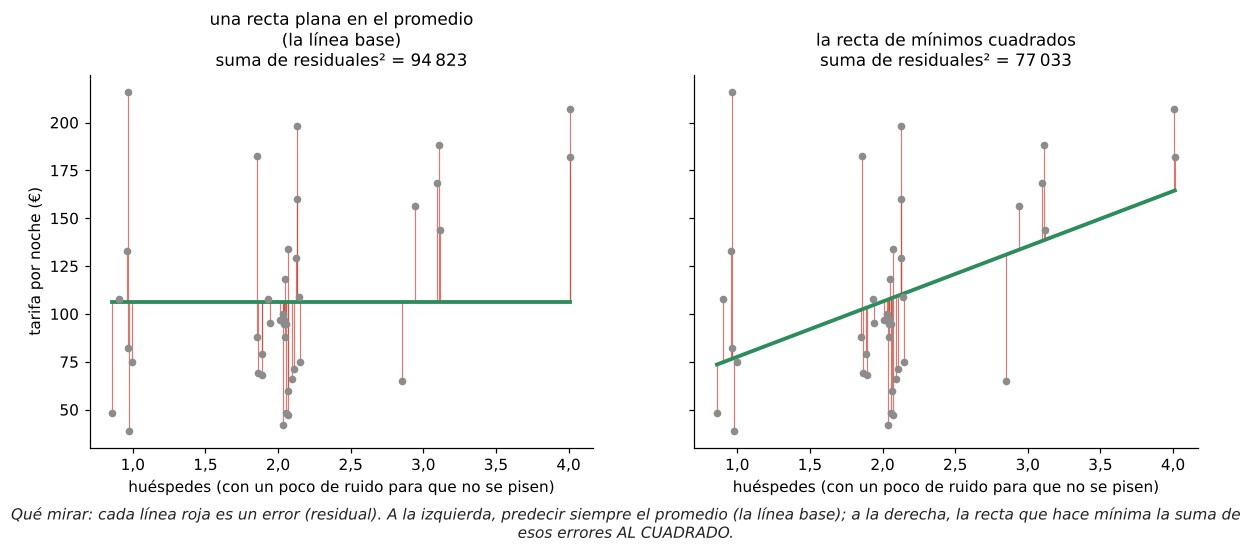

In [44]:
muestra = df.sample(40, random_state=3)
fg.recta_residuales(muestra["huespedes"] + np.random.default_rng(0).uniform(-0.15, 0.15, 40), muestra["adr"],
                    malas=((df["adr"].mean(), 0.0), None), xlabel="huéspedes (con un poco de ruido para que no se pisen)",
                    ylabel="tarifa por noche (€)");

In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# La y ahora es la tarifa: se quitan de X las columnas que la contienen (adr y adr_por_persona serían fuga)
X_reg = X.drop(columns=["adr", "adr_por_persona"])
y_reg = df["adr"]
num_r = X_reg.select_dtypes("number").columns.tolist(); cat_r = X_reg.select_dtypes(exclude="number").columns.tolist()

resultados_reg = {}
for nombre, modelo in [("línea base (promedio)", DummyRegressor(strategy="mean")), ("regresión lineal", LinearRegression())]:
    m = Pipeline([("pre", crear_preprocesador(num_r, cat_r)), ("modelo", modelo)])
    m.fit(X_reg.loc[X_ent.index], y_reg.loc[X_ent.index])                 # las MISMAS filas de entrenamiento…
    pred = m.predict(X_reg.loc[X_val.index]); real = y_reg.loc[X_val.index]   # …y de validación
    resultados_reg[nombre] = {"MAE (€)": mean_absolute_error(real, pred),
                              "RMSE (€)": mean_squared_error(real, pred) ** 0.5, "R²": r2_score(real, pred)}
    if nombre == "regresión lineal":
        regresion, pred_reg = m, pred
pd.DataFrame(resultados_reg).T.round(2)

,MAE (€),RMSE (€),R²
línea base (promedio),39.40,51.32,-0.00
regresión lineal,28.27,38.62,0.43


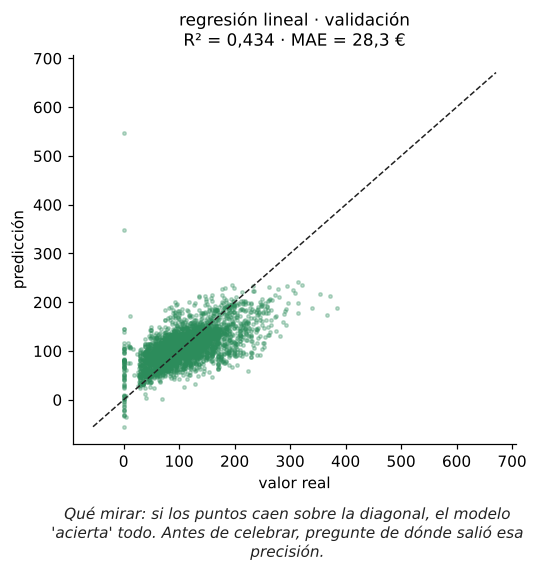

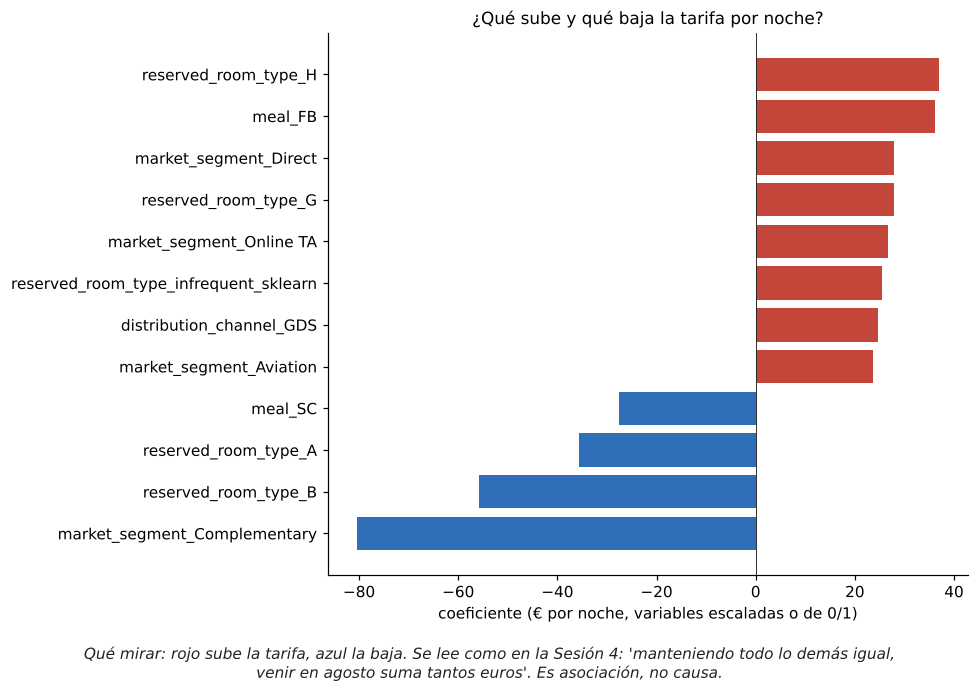

In [46]:
fg.pred_vs_real({"regresión lineal · validación": (y_reg.loc[X_val.index], pred_reg)}, unidad=" €");
coef_r = pd.Series(regresion.named_steps["modelo"].coef_, index=regresion.named_steps["pre"].get_feature_names_out())
coef_r = coef_r.reindex(coef_r.abs().sort_values(ascending=False).index).head(12)
barras_horizontales(coef_r, "¿Qué sube y qué baja la tarifa por noche?", "coeficiente (€ por noche, variables escaladas o de 0/1)",
                    "rojo sube la tarifa, azul la baja. Se lee como en la Sesión 4: 'manteniendo todo lo demás igual, venir en "
                    "agosto suma tantos euros'. Es asociación, no causa.");

**Lectura.** La regresión lineal le gana con claridad al promedio (el MAE baja y el R² pasa de 0 a algo apreciable), pero deja mucho sin explicar: los precios de un hotel dependen de cosas que no están en los datos (eventos, ocupación del día, la tarifa de la competencia). Los coeficientes se leen en euros, y esa es la gran virtud del modelo lineal: **se explica solo**. Todo lo que sigue (validación cruzada, búsqueda, prueba final) funciona igual para regresión, cambiando AUC por MAE o RMSE.

## 13. Agrupar sin la *y*: PCA y K-means (Sesiones 7–9) 📦 E3

Hasta aquí todo fue **supervisado**: había una *y* que imitar. La entrega E3 pide otra pregunta: **sin mirar la *y***, ¿qué tipos de reserva hay? Esto sirve, por ejemplo, para que el hotel diseñe ofertas distintas para cada tipo de cliente.

Reglas del juego (las mismas de la rúbrica de E3):

1. Se eligen columnas que describan la reserva, **sin la *y*** y sin identificadores.
2. Se escalan (K-means y PCA miden distancias y varianzas).
3. La *y* solo se mira **al final**, para leer los grupos (validación externa).

Usamos una muestra de 5 000 reservas de entrenamiento para que corra rápido y las figuras se lean.

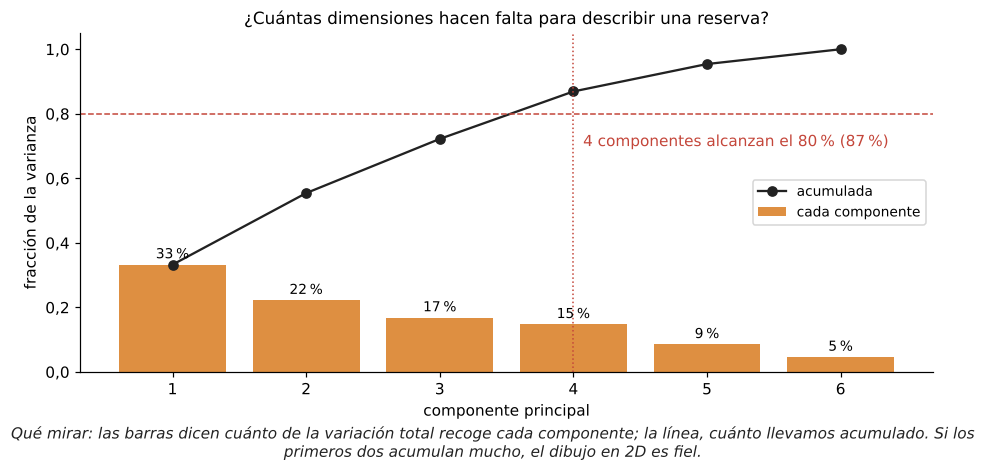

In [47]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cols_seg = ["lead_time", "noches_totales", "adr_por_persona", "huespedes", "total_of_special_requests", "con_ninos"]
seg = X_ent[cols_seg].sample(5_000, random_state=SEMILLA).copy()
seg = seg.clip(upper=seg.quantile(0.995), axis=1)   # recorta los extremos: un solo grupo de 20 huéspedes no debe mover todo el PCA
seg_z = StandardScaler().fit_transform(seg.assign(lead_time=np.log1p(seg["lead_time"]),
                                                  noches_totales=np.log1p(seg["noches_totales"])))

pca = PCA().fit(seg_z)
fg.pca_varianza(pca, marcar=0.8, titulo="¿Cuántas dimensiones hacen falta para describir una reserva?");

Silueta por k: {2: 0.421, 3: 0.28, 4: 0.278, 5: 0.253, 6: 0.236}


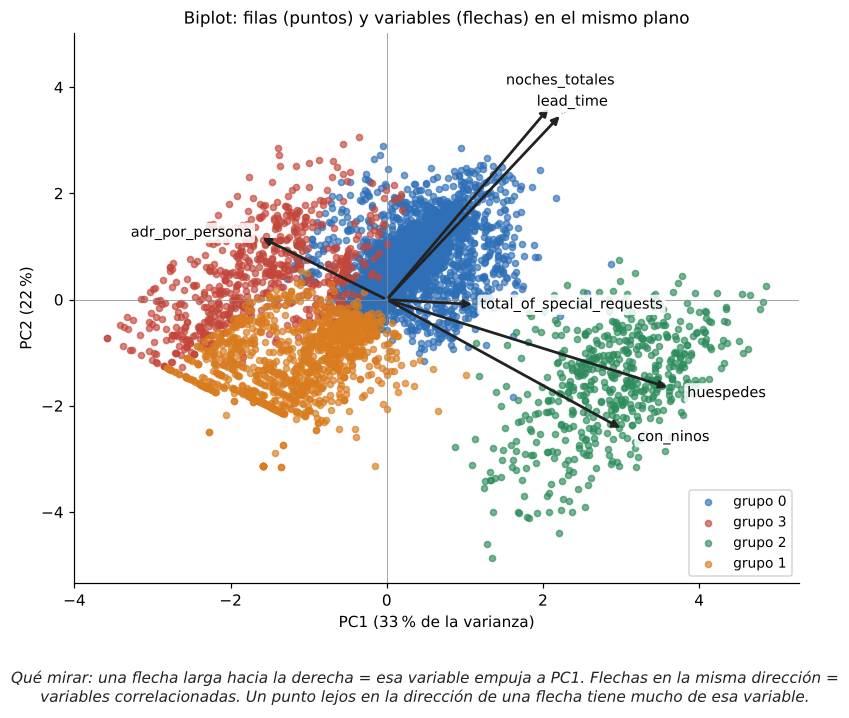

In [48]:
siluetas = {k: silhouette_score(seg_z, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(seg_z)) for k in range(2, 7)}
print("Silueta por k:", {k: round(v, 3) for k, v in siluetas.items()})
k = 4      # la silueta prefiere k = 2, pero dos grupos dicen poco; entre 3 y 5 es casi igual y 4 grupos se pueden nombrar y usar
km = KMeans(k, n_init=10, random_state=SEMILLA).fit(seg_z)
grupo = pd.Series(km.labels_, index=seg.index)

scores = pca.transform(seg_z)
fg.biplot(scores, pca.components_, cols_seg, etiquetas=[f"grupo {g}" for g in grupo],
          var_exp=pca.explained_variance_ratio_);

La silueta más alta es la de *k* = 2, pero dos grupos separan casi solo "con niños / sin niños": correcto y poco útil. Entre 3 y 5 la silueta es casi la misma, así que elegimos 4 por **utilidad**: son grupos que el hotel puede nombrar y atender distinto. Es una decisión, y se escribe como decisión.

**Perfil de cada grupo** (promedios en las unidades originales) y, **solo ahora**, la validación externa: ¿cancelan distinto?

In [49]:
perfil = seg.groupby(grupo).mean().round(1)
perfil["reservas"] = grupo.value_counts().sort_index()
perfil["% que cancela (y, solo para leer)"] = (y_ent.loc[seg.index].groupby(grupo).mean() * 100).round(1)
perfil

,lead_time,noches_totales,adr_por_persona,huespedes,total_of_special_requests,con_ninos,reservas,"% que cancela (y, solo para leer)"
0,115.2,4.5,49.0,2.1,0.7,0.0,2658,32.6
1,9.1,1.6,44.6,1.7,0.5,0.0,1145,13.8
2,88.0,3.9,46.8,3.4,0.9,1.0,542,38.0
3,46.8,2.7,108.5,1.2,0.5,0.0,655,26.3


**Lectura.** Cada grupo se puede describir con palabras mirando su fila, por ejemplo: "familias con niños", "estadías largas reservadas con mucha anticipación", "viajes cortos de última hora". Lo interesante es que, **sin haber visto la *y***, los grupos cancelan en proporciones distintas: la segmentación captura algo del comportamiento.

**Lo que *no* se puede concluir:** que estos sean "los" tipos de cliente (con otras columnas, otra semilla u otro *k* saldrían otros grupos; en S9 medimos la estabilidad); que pertenecer a un grupo *cause* la cancelación; ni que 4 sea el número correcto (lo elegimos por utilidad, no porque los datos lo impongan).

> 📦 **En su proyecto (E3):** justifique cada columna, escale, argumente el *k* (codo, silueta, **estabilidad** y utilidad), ponga nombre a cada grupo, valídelos con algo externo y escriba al menos tres frases de lo que **no** se puede concluir.

## 14. Comparación justa: validación cruzada (Sesión 10) 📦 E4

La tabla de la sección 11 salió de **una** validación. Con otra partición al azar, los números cambiarían un poco. ¿Las diferencias entre modelos son reales o son suerte del sorteo?

La **validación cruzada** (*k-fold*) responde eso: parte el entrenamiento completo en 5 pedazos, entrena 5 veces dejando cada vez un pedazo distinto para validar, y reporta el **promedio ± la desviación**. La prueba sigue bajo llave.

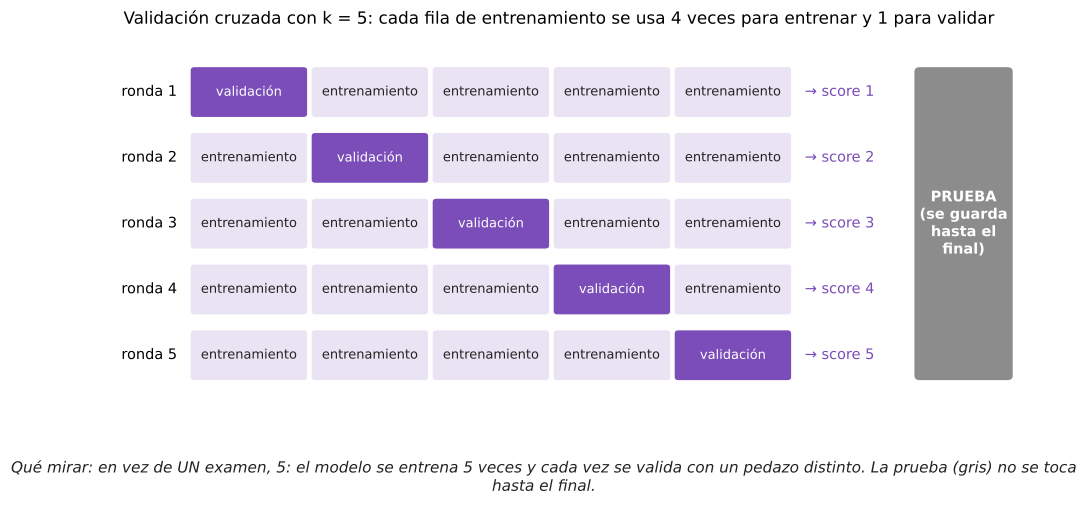

In [50]:
fg.cv_folds(k=5);

In [51]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
candidatos = {
    "línea base": DummyClassifier(strategy="most_frequent"),
    "árbol": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    "logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "bosque": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEMILLA),
    "boosting": HistGradientBoostingClassifier(random_state=SEMILLA),
}
cv_auc = {}
for nombre, modelo in candidatos.items():
    t = time.time()
    r = cross_validate(Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", modelo)]),
                       X_ent_completo, y_ent_completo, cv=cv, scoring="roc_auc")
    cv_auc[nombre] = r["test_score"]
    print(f"{nombre:11s} AUC = {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}   ({time.time() - t:.0f} s)")

línea base  AUC = 0.500 ± 0.000   (2 s)


árbol       AUC = 0.834 ± 0.005   (4 s)


logística   AUC = 0.821 ± 0.004   (4 s)


bosque      AUC = 0.872 ± 0.004   (35 s)


boosting    AUC = 0.868 ± 0.004   (12 s)


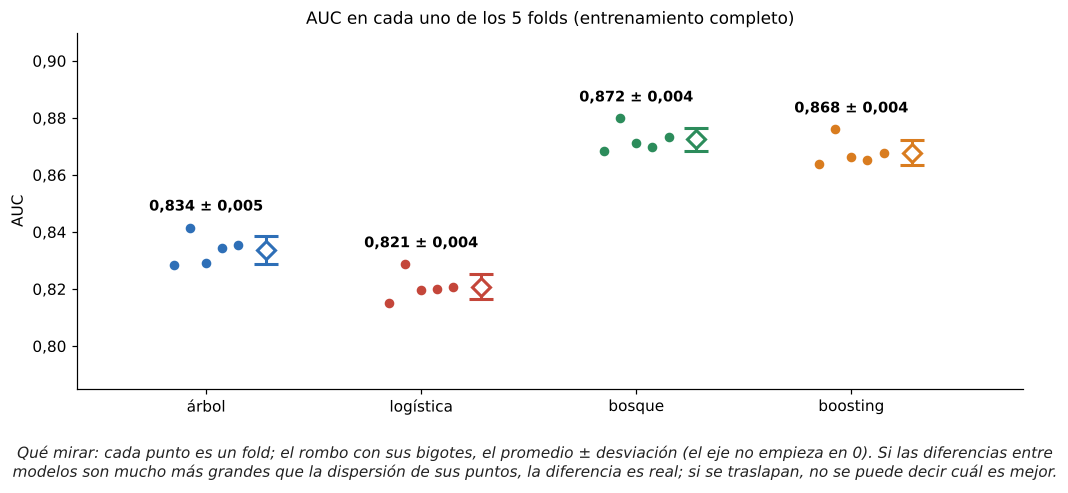

In [52]:
fg.cv_scores({n: v for n, v in cv_auc.items() if n != "línea base"}, metrica="AUC",
             titulo="AUC en cada uno de los 5 folds (entrenamiento completo)");

**Lectura.** Los puntos de cada modelo están muy juntos (desviaciones pequeñas): con tantas reservas, el sorteo pesa poco. Las diferencias entre la logística, el árbol y los modelos de muchos árboles son mucho más grandes que esa dispersión: **son reales**. Entre bosque y boosting la diferencia es pequeña. Elegimos **boosting** para afinar porque es igual de bueno, más rápido de entrenar y tiene perillas que vale la pena explorar.

> 📦 **En su proyecto (E4):** línea base + al menos tres modelos (incluido *gradient boosting*), todos con validación cruzada, reportados como promedio ± desviación.

## 15. Afinar hiperparámetros (Sesión 11) 📦 E4

Los **hiperparámetros** son las perillas que el `.fit()` no aprende solo (`learning_rate`, profundidad…). Se eligen probando combinaciones **con validación cruzada dentro del entrenamiento**, nunca mirando la prueba.

`RandomizedSearchCV` prueba combinaciones al azar dentro de los rangos que le damos. Con 8 intentos y 3 folds son 24 entrenamientos: un par de minutos. En la Sesión 11 vemos **Optuna**, que aprende de cada intento dónde conviene buscar.

🔍 **Predice:** ¿cuánto cree que va a subir el AUC al afinar: más de 0,05, entre 0,01 y 0,05, o menos de 0,01?

In [53]:
from sklearn.model_selection import RandomizedSearchCV

busqueda = RandomizedSearchCV(
    Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", HistGradientBoostingClassifier(random_state=SEMILLA))]),
    param_distributions={
        "modelo__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "modelo__max_leaf_nodes": [15, 31, 63, 127],
        "modelo__min_samples_leaf": [10, 20, 50, 100],
        "modelo__l2_regularization": [0.0, 0.1, 1.0],
        "modelo__max_iter": [300, 600],          # con early stopping: se detiene solo cuando deja de mejorar
    },
    n_iter=8, cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA), scoring="roc_auc",
    random_state=SEMILLA, n_jobs=1)
t = time.time()
busqueda.fit(X_ent_completo, y_ent_completo)
print(f"Búsqueda: {time.time() - t:.0f} s")
print(f"Mejor AUC en validación cruzada: {busqueda.best_score_:.3f}   (boosting por defecto: {cv_auc['boosting'].mean():.3f})")
print("Mejores perillas:", {k.replace('modelo__', ''): v for k, v in busqueda.best_params_.items()})

Búsqueda: 105 s
Mejor AUC en validación cruzada: 0.873   (boosting por defecto: 0.868)
Mejores perillas: {'min_samples_leaf': 10, 'max_leaf_nodes': 127, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 1.0}


In [54]:
intentos = (pd.DataFrame(busqueda.cv_results_)
              .sort_values("mean_test_score", ascending=False)
              [["mean_test_score", "std_test_score"] + [c for c in busqueda.cv_results_ if c.startswith("param_")]])
intentos.columns = [c.replace("param_modelo__", "") for c in intentos.columns]
intentos.round(4).head(8)

,mean_test_score,std_test_score,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization
0,0.8730,0.0004,10,127,300,0.03,1.0
3,0.8727,0.0001,10,127,300,0.10,1.0
4,0.8710,0.0011,10,63,600,0.05,0.0
1,0.8704,0.0003,50,63,600,0.20,0.1
5,0.8672,0.0008,10,31,600,0.20,1.0
2,0.8671,0.0007,100,15,300,0.20,1.0
7,0.8665,0.0018,50,15,600,0.20,0.0
6,0.8619,0.0009,20,15,300,0.05,0.0


**Lectura.** Afinar ayuda, pero **poco** comparado con elegir un buen tipo de modelo: la gran ganancia fue pasar de la logística a los árboles en conjunto (sección 14). Es lo normal. Por eso en la presentación se reporta la ganancia de afinar sin exagerarla.

## 16. El umbral y la prueba final (una sola vez) 📦 E4

**Primero el umbral, sin tocar la prueba.** El modelo da probabilidades; el hotel necesita decidir a partir de qué probabilidad trata una reserva como "probable cancelación". Para elegirlo usamos predicciones **fuera de fold** del entrenamiento completo (`cross_val_predict`): cada reserva recibe la probabilidad de un modelo que no la vio.

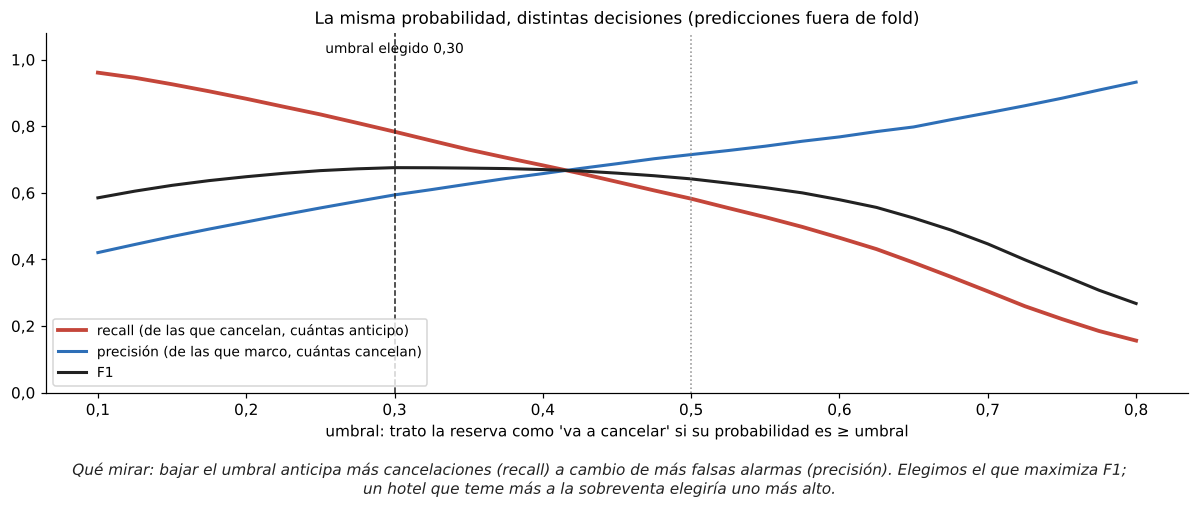

In [55]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

proba_oof = cross_val_predict(clone(busqueda.best_estimator_), X_ent_completo, y_ent_completo, cv=cv, method="predict_proba")[:, 1]

umbrales = np.round(np.arange(0.10, 0.81, 0.025), 3)
curvas = pd.DataFrame({u: {"recall": recall_score(y_ent_completo, proba_oof >= u),
                           "precisión": precision_score(y_ent_completo, proba_oof >= u, zero_division=0),
                           "F1": f1_score(y_ent_completo, proba_oof >= u)} for u in umbrales}).T
UMBRAL = float(curvas["F1"].idxmax())

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(curvas.index, curvas["recall"], color=fg.ROJO, lw=2.5, label="recall (de las que cancelan, cuántas anticipo)")
ax.plot(curvas.index, curvas["precisión"], color=fg.AZUL, lw=2, label="precisión (de las que marco, cuántas cancelan)")
ax.plot(curvas.index, curvas["F1"], color=fg.NEGRO, lw=2, label="F1")
ax.axvline(0.5, color=fg.GRIS, ls=":", lw=1); ax.axvline(UMBRAL, color=fg.NEGRO, ls="--", lw=1)
ax.text(UMBRAL, 1.02, f"umbral elegido {UMBRAL:.2f}", ha="center", fontsize=9)
ax.set_xlabel("umbral: trato la reserva como 'va a cancelar' si su probabilidad es ≥ umbral"); ax.set_ylim(0, 1.08)
ax.legend(loc="lower left"); ax.set_title("La misma probabilidad, distintas decisiones (predicciones fuera de fold)"); fig.tight_layout()
fg._leyenda(fig, "bajar el umbral anticipa más cancelaciones (recall) a cambio de más falsas alarmas (precisión). Elegimos el que "
                 "maximiza F1; un hotel que teme más a la sobreventa elegiría uno más alto.");

**Ahora sí, la prueba.** Se abre **una sola vez**, con todo decidido: el modelo, sus perillas y el umbral. Evaluamos también los otros candidatos (entrenados con el entrenamiento completo) para tener la comparación honesta de la presentación.

🔍 **Predice:** ¿el AUC en prueba del modelo afinado será mayor, igual o menor que su AUC en validación cruzada?

In [56]:
final = busqueda.best_estimator_          # RandomizedSearchCV ya lo reentrenó con TODO el entrenamiento completo
filas = {}
for nombre in ["línea base", "logística", "bosque", "boosting"]:
    m = Pipeline([("pre", crear_preprocesador(num, cat)), ("modelo", clone(candidatos[nombre]))]).fit(X_ent_completo, y_ent_completo)
    filas[nombre] = (cv_auc[nombre].mean(), cv_auc[nombre].std(), roc_auc_score(y_prueba, m.predict_proba(X_prueba)[:, 1]))
auc_prueba_final = roc_auc_score(y_prueba, final.predict_proba(X_prueba)[:, 1])
filas["boosting afinado"] = (busqueda.best_score_, busqueda.cv_results_["std_test_score"][busqueda.best_index_], auc_prueba_final)

comparacion = pd.DataFrame(filas, index=["AUC validación cruzada", "± desviación", "AUC prueba"]).T
comparacion.round(3)

,AUC validación cruzada,± desviación,AUC prueba
línea base,0.500,0.000,0.500
logística,0.821,0.004,0.827
bosque,0.872,0.004,0.878
boosting,0.868,0.004,0.873
boosting afinado,0.873,0.000,0.882


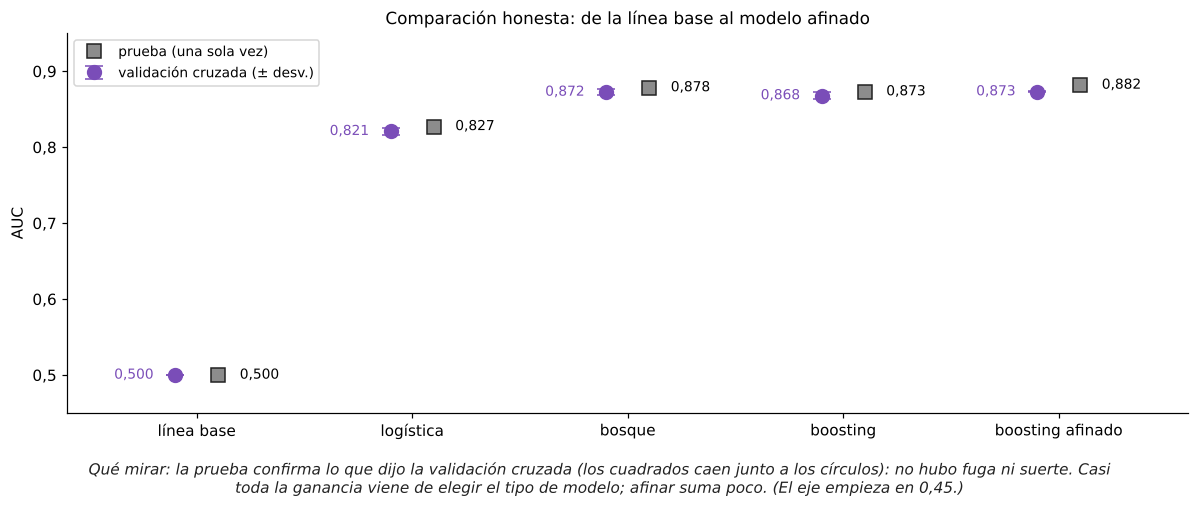

In [57]:
fig, ax = plt.subplots(figsize=(11, 4.2))
xs = np.arange(len(comparacion))
ax.errorbar(xs - 0.1, comparacion.iloc[:, 0], yerr=comparacion.iloc[:, 1], fmt="o", ms=9, capsize=6, color=fg.MODULO[4],
            label="validación cruzada (± desv.)")
ax.plot(xs + 0.1, comparacion.iloc[:, 2], "s", ms=9, color=fg.GRIS, mec=fg.NEGRO, label="prueba (una sola vez)")
for x, a, b in zip(xs, comparacion.iloc[:, 0], comparacion.iloc[:, 2]):
    ax.text(x - 0.2, a, f"{a:.3f}", ha="right", va="center", fontsize=9, color=fg.MODULO[4])
    ax.text(x + 0.2, b, f"{b:.3f}", ha="left", va="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(comparacion.index); ax.set_ylabel("AUC"); ax.set_ylim(0.45, 0.95)
ax.set_xlim(-0.6, len(xs) - 0.4); ax.legend(loc="upper left"); ax.set_title("Comparación honesta: de la línea base al modelo afinado"); fig.tight_layout()
fg._leyenda(fig, "la prueba confirma lo que dijo la validación cruzada (los cuadrados caen junto a los círculos): no hubo fuga ni "
                 "suerte. Casi toda la ganancia viene de elegir el tipo de modelo; afinar suma poco. (El eje empieza en 0,45.)");

Con el umbral elegido, en prueba: recall 79.2% · precisión 59.8% · F1 0.682


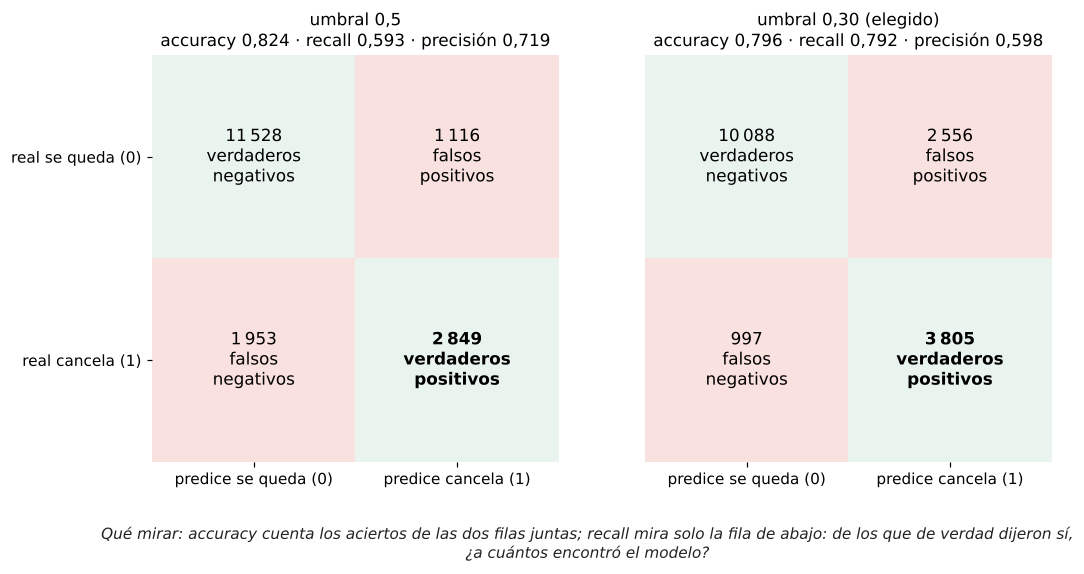

In [58]:
pred_final = (final.predict_proba(X_prueba)[:, 1] >= UMBRAL).astype(int)
fg.matrices_confusion({"umbral 0,5": (y_prueba, final.predict(X_prueba)),
                       f"umbral {UMBRAL:.2f} (elegido)": (y_prueba, pred_final)},
                      etiquetas=("se queda (0)", "cancela (1)"));
print(f"Con el umbral elegido, en prueba: recall {recall_score(y_prueba, pred_final):.1%} · "
      f"precisión {precision_score(y_prueba, pred_final):.1%} · F1 {f1_score(y_prueba, pred_final):.3f}")

> 📦 **En su proyecto (E4):** **una sola** evaluación en prueba, comparada con la validación cruzada y con su modelo de E2. Si el número de prueba es mucho peor que el de validación cruzada, algo se filtró o la prueba es distinta (búsquelo antes de presentar). Si es mucho mejor, también desconfíe.

## 17. ¿Qué aprendió el modelo? Interpretación (Sesión 11) 📦 E4

**Importancia por permutación.** Se toma la prueba, se **desordena** una columna (se rompe su relación con la *y*) y se mide cuánto cae el AUC. Si cae mucho, el modelo dependía de esa columna. Tiene una ventaja sobre la importancia de Gini: funciona con cualquier modelo y se mide en las **columnas originales**, no en las de 0/1.

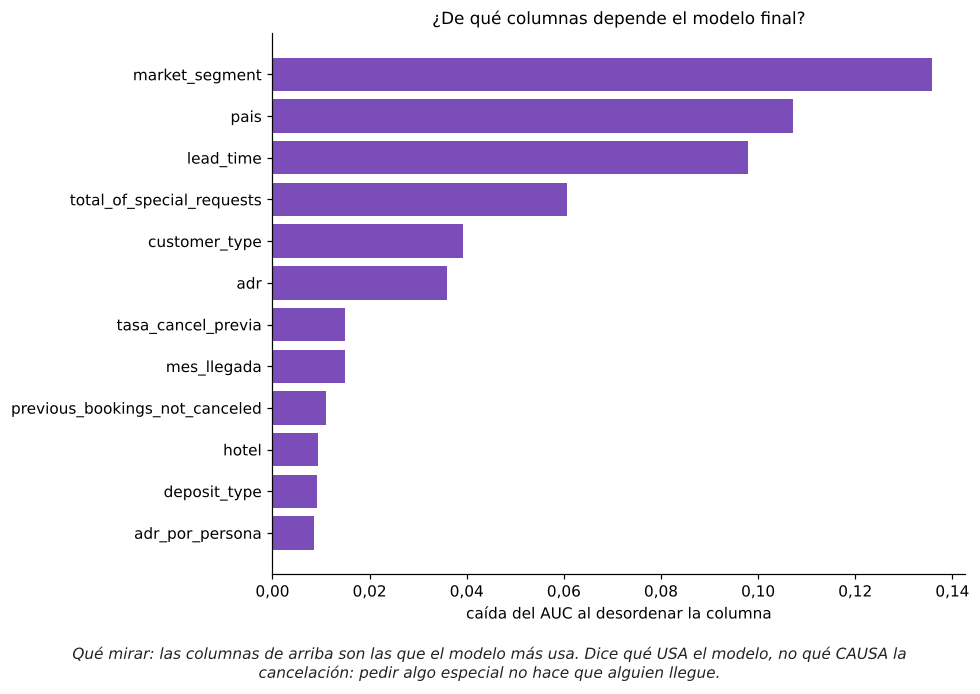

In [59]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final, X_prueba, y_prueba, scoring="roc_auc", n_repeats=5, random_state=SEMILLA, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=X_prueba.columns).sort_values().tail(12)
barras_horizontales(imp_perm, "¿De qué columnas depende el modelo final?", "caída del AUC al desordenar la columna",
                    "las columnas de arriba son las que el modelo más usa. Dice qué USA el modelo, no qué CAUSA la cancelación: "
                    "pedir algo especial no hace que alguien llegue.", color=fg.MODULO[4]);

**Lectura.** Las columnas que más usa el modelo coinciden con lo que vimos en la exploración: el segmento, el país, la anticipación y las peticiones especiales. Que el modelo y el EDA cuenten la misma historia es una buena señal. ¿Y el depósito, que en la pregunta 4 parecía tan fuerte? Aparece abajo **no porque no importe**, sino porque su información ya está en otras columnas (casi todas las reservas no reembolsables son de ciertos segmentos y agencias). Cuando dos columnas dicen lo mismo, desordenar solo una casi no duele: es una limitación de la importancia por permutación que hay que conocer. En la Sesión 11 vemos **SHAP**, que además explica cada predicción individual.

**Una reserva entra, una probabilidad sale.** Tres reservas de prueba, con lo que el modelo dice de cada una:

In [60]:
proba_prueba = pd.Series(final.predict_proba(X_prueba)[:, 1], index=X_prueba.index).sort_values()
ejemplos = X_prueba.loc[[proba_prueba.index[int(q * (len(proba_prueba) - 1))] for q in (0.15, 0.6, 0.95)]]   # riesgo bajo, medio y alto
vista = ejemplos[["hotel", "lead_time", "market_segment", "deposit_type", "pais", "total_of_special_requests", "noches_totales"]].copy()
vista["prob. de cancelar"] = final.predict_proba(ejemplos)[:, 1].round(2)
vista["decisión"] = np.where(vista["prob. de cancelar"] >= UMBRAL, "probable cancelación", "probable llegada")
vista["lo que pasó"] = y_prueba.loc[ejemplos.index].map({0: "llegó", 1: "canceló"})
vista

,hotel,lead_time,market_segment,deposit_type,pais,total_of_special_requests,noches_totales,prob. de cancelar,decisión,lo que pasó
15288,Resort Hotel,0,Direct,No Deposit,PRT,1,3,0.01,probable llegada,llegó
40404,City Hotel,98,Online TA,No Deposit,PRT,1,2,0.26,probable llegada,canceló
38382,Resort Hotel,349,Online TA,No Deposit,Otros,1,7,0.81,probable cancelación,llegó


👀 **Mire** la última columna: el modelo **se equivoca** con algunas reservas, y eso es normal. Una probabilidad de 80 % no promete que *esta* reserva se cancele: dice que, de cada 10 reservas parecidas, unas 8 se cancelan. Un modelo de clasificación acierta en promedio, no caso por caso. Por eso se usa para **priorizar** (a quién llamar primero), no para decidir a ciegas sobre una persona.

## 18. Guardar el modelo y usarlo con reservas nuevas 📦 E4

El `Pipeline` completo (preprocesamiento + modelo) se guarda en **un solo archivo** con `joblib`. Quien lo cargue le pasa reservas **crudas**, con las mismas columnas de `X`, y el `Pipeline` hace todo lo demás.

In [61]:
import joblib

joblib.dump(final, "modelo_cancelaciones.joblib")
cargado = joblib.load("modelo_cancelaciones.joblib")

# Una reserva nueva, inventada: hotel de ciudad, reservada con 200 días de anticipación por agencia en línea
nueva = X_prueba.iloc[[0]].copy()
nueva[["hotel", "lead_time", "market_segment", "distribution_channel", "deposit_type", "pais", "total_of_special_requests"]] = \
      ["City Hotel", 200, "Online TA", "TA/TO", "No Deposit", "PRT", 0]
p = cargado.predict_proba(nueva)[0, 1]
print(f"Probabilidad de cancelar: {p:.0%} → {'probable cancelación' if p >= UMBRAL else 'probable llegada'}")

Probabilidad de cancelar: 82% → probable cancelación


> 📦 **En su proyecto (E4):** guarde su `Pipeline` con `joblib` y deje una celda que lo carga y predice una fila nueva. En la Sesión 12 se hace la "prueba de humo": cargar su archivo y predecir.

## 19. Límites y conclusión de negocio 📦 Presentación

Un resultado sin límites no es honesto. Estos son los de este proyecto:

In [62]:
print("Resumen en números")
print(f"· Línea base (nadie cancela): AUC 0,50 · accuracy {accuracy_score(y_prueba, np.zeros_like(y_prueba)):.1%} · recall 0 %")
print(f"· Modelo final (boosting afinado): AUC en prueba {auc_prueba_final:.3f}  "
      f"(validación cruzada {busqueda.best_score_:.3f})")
print(f"· Con el umbral {UMBRAL:.2f}: anticipa el {recall_score(y_prueba, pred_final):.0%} de las cancelaciones, "
      f"y de cada 10 reservas marcadas, unas {10 * precision_score(y_prueba, pred_final):.0f} sí cancelan")

Resumen en números
· Línea base (nadie cancela): AUC 0,50 · accuracy 72.5% · recall 0 %
· Modelo final (boosting afinado): AUC en prueba 0.882  (validación cruzada 0.873)
· Con el umbral 0.30: anticipa el 79% de las cancelaciones, y de cada 10 reservas marcadas, unas 6 sí cancelan


**Límites: lo que *no* se puede concluir**

1. **Dos hoteles de Portugal, 2015–2017.** No sabemos si el modelo funciona en un hotel de Cartagena o en 2027. Los patrones (anticipación, canal, temporada) probablemente se parecen; los números exactos, no.
2. **La partición fue al azar, no en el tiempo.** El modelo se usaría con reservas *futuras*. Una evaluación más exigente entrenaría con 2015–2016 y probaría con 2017. Es probable que el resultado empeore un poco.
3. **Rarezas sin explicar.** El 99 % de cancelación con depósito no reembolsable y las columnas que podrían actualizarse después de reservar (`total_of_special_requests`) son puntos débiles. Lo honesto es decirlo, no esconderlo.
4. **Los duplicados.** Los quitamos porque no podíamos distinguir reservas de grupo de copias. Si eran reservas reales, cambiamos la proporción de la *y* (del 37 % al 27,5 %).
5. **Importancia ≠ causa.** Que las peticiones especiales bajen el riesgo no significa que ofrecer peticiones especiales reduzca las cancelaciones.

**Conclusión para el hotel (en lenguaje de negocio)**

> Con la información disponible al momento de la reserva, el modelo ordena bien las reservas por riesgo de cancelación: mucho mejor que el azar y que cualquier regla simple. Con el umbral elegido anticipa la mayoría de las cancelaciones, con un margen de falsas alarmas que hay que pesar contra el costo de una habitación vacía. La recomendación es usarlo para **priorizar llamadas de confirmación** y para **calibrar cuánto sobrevender**, nunca para negar una reserva, y volver a evaluarlo con datos recientes del propio hotel antes de confiar en él.

> 📦 **En su presentación (S12):** 4 láminas: (1) la pregunta y la métrica; (2) los datos, el pipeline y qué trampa evitó; (3) el resultado honesto (línea base → E2 → final, validación cruzada ± y prueba); (4) un error que cometió y qué **no** se puede concluir.

## 20. La guía en una página: lista de chequeo del proyecto

| ✔ | Paso | Pregunta de control | Sección |
|---|---|---|---|
| ☐ | Problema | ¿Qué es una fila, cuál es la *y*, cuándo se usaría el modelo y qué cuesta cada error? | 1 |
| ☐ | Primera mirada | ¿Tipos, vacíos, duplicados y proporción (o rango) de la *y*? | 2 |
| ☐ | EDA | ¿Cada gráfica responde una pregunta y tiene su lectura escrita? | 3 |
| ☐ | Fuga | ¿Revisé columna por columna qué se conoce **después** de la *y*? ¿Hay alguna "regla del 0 %"? | 4, 9 |
| ☐ | Limpieza | ¿Cada decisión tiene su por qué? ¿Revisé si cambió la proporción de la *y*? | 5 |
| ☐ | *Feature engineering* | ¿Las variables nuevas usan solo información de la misma fila (o se calculan solo con entrenamiento)? | 6 |
| ☐ | Partición | ¿Separé la prueba **antes** de todo, estratificando? | 7 |
| ☐ | `Pipeline` | ¿Todo lo que aprende de los datos va dentro del `Pipeline`? | 8 |
| ☐ | Línea base | ¿Mi modelo le gana con claridad a `Dummy`? ¿Elegí una métrica que no engañe? | 9 |
| ☐ | Desbalance | ¿Comparé con y sin ajuste? ¿Balanceo solo dentro del `Pipeline`? | 10 |
| ☐ | Modelos | ¿Cada modelo tiene una figura que muestra qué aprendió? | 11–12 |
| ☐ | No supervisado | ¿Columnas sin la *y*, escaladas, *k* argumentado, grupos con nombre y límites? | 13 |
| ☐ | Validación cruzada | ¿Comparé al menos 3 modelos con promedio ± desviación? | 14 |
| ☐ | Búsqueda | ¿Afiné solo con validación cruzada, sin mirar la prueba? | 15 |
| ☐ | Prueba | ¿La abrí **una sola vez**, con modelo, perillas y umbral ya decididos? | 16 |
| ☐ | Interpretación | ¿Dije qué usa el modelo y advertí que no es causalidad? | 17 |
| ☐ | Guardar | ¿El `.joblib` se carga y predice una fila nueva? | 18 |
| ☐ | Límites | ¿Escribí lo que **no** se puede concluir? | 19 |

**Siguiente paso:** abra la **plantilla del proyecto** (`proyecto/plantilla_proyecto.ipynb`). Tiene estas mismas secciones, vacías, para su dataset. Llene cada una después de la sesión que la cubre.

In [63]:
print(f"Notebook completo en {(time.time() - INICIO) / 60:.1f} minutos.")

Notebook completo en 5.3 minutos.
